# Two-flow PHY adaptation analysis (s1 + s2 + s3)

Read-only analysis of `tmp/two_flow_sweep/` — a 13 440-run sweep over **(scenario × condition × μ × w × MCS × seed)** with **two flows**:

| Flow | Port | Prio | Rate     | RRI / PDB        | Sched | Lifetime              |
|------|------|------|----------|------------------|-------|-----------------------|
| `cam`  (platoon control) | 8001 | 1 | 200 kbps | 20 ms / 10 ms    | DG    | full sim (~2 → 24 s)  |
| `vid`  (HD video)        | 8002 | 3 | 2 Mbps   | 100 ms / 50 ms   | SPS   | burst 7 → 24 s        |

Single Tx (`tx_nodes=0`), HARQ enabled with `maxNumTx=4`, PSFCH every 4 slots.

**Sections**
0. Setup, data loading, **caveats**
1. PRR + PIR vs scenario iteration, faceted by PHY config
2. Per-receiver best MCS — 1F (cam) vs 2F (vid)
3. Optimal MCS at each (μ, w) per scenario iteration
4. PRR/PIR vs MCS, comparing the two flows
5. Optimal (μ, w, MCS) leaderboards — 1F vs 2F vs joint-min
6. Bonus analyses (cam degradation, Pareto, fairness, robustness, throughput efficiency)

## §0 — Setup, data loading, caveats

In [2]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(context='notebook', style='whitegrid')
plt.rcParams['figure.dpi'] = 110
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 220)

NB_DIR = Path.cwd()
REPO = NB_DIR.parents[3]
TMP = REPO / 'tmp' / 'two_flow_sweep'
assert TMP.exists(), f'sweep dir missing: {TMP}'
print('repo  :', REPO)
print('sweep :', TMP)

repo  : /Users/hadih/Documents/groupcast-adaptation-ns3
sweep : /Users/hadih/Documents/groupcast-adaptation-ns3/tmp/two_flow_sweep


In [3]:
# Load per-run KPIs and per-rx KPIs.
# IMPORTANT: _kpi_summary.csv was concatenated with a glob (*_kpi.csv) that
# accidentally also matched per-rx files, polluting the file with rows that
# have run-only columns blank. Filter on tx_count.notna() to keep only
# genuine per-(run, flow) rows.
df_run = pd.read_csv(TMP / '_kpi_summary.csv')
before = len(df_run)
df_run = df_run[df_run['tx_count'].notna()].copy()
print(f'df_run: {len(df_run)} clean rows (dropped {before - len(df_run)} polluted)')

df_rx = pd.read_csv(TMP / '_per_rx_kpi_summary.csv')
print(f'df_rx : {len(df_rx)} rows')

df_run: 26880 clean rows (dropped 211564 polluted)
df_rx : 211564 rows


In [4]:
# Map scenario condition strings to a numeric x-axis value.
S1_RE = re.compile(r'^nrx(\d+)$')
S2_RE = re.compile(r'^ivd(\d+)m$')
S3_RE = re.compile(r'^spd(\d+)kmh$')

def cond_to_value(scen, cond):
    if scen == 's1':
        m = S1_RE.match(cond);  return int(m.group(1)) if m else np.nan
    if scen == 's2':
        m = S2_RE.match(cond);  return int(m.group(1)) if m else np.nan
    if scen == 's3':
        m = S3_RE.match(cond);  return int(m.group(1)) if m else np.nan
    return np.nan

SCEN_AXIS = {
    's1': ('Number of receivers (UEs)', 'n_ues'),
    's2': ('Inter-vehicle distance (m)', 'ivd_m'),
    's3': ('Vehicle speed (km/h)', 'speed_kmh'),
}

for df in (df_run, df_rx):
    df['iter_value'] = df.apply(lambda r: cond_to_value(r['scen'], r['cond']), axis=1)

# HARQ NACK rate (run-level, totals are correct on df_run; df_rx HARQ columns are unusable per the known attribution bug).
denom = (df_run['harq_ack'].fillna(0) + df_run['harq_nack'].fillna(0)).replace(0, np.nan)
df_run['harq_nack_rate'] = df_run['harq_nack'] / denom

print('scenarios :', sorted(df_run['scen'].unique()))
print('flows     :', sorted(df_run['flow'].unique()))
print('mu values :', sorted(df_run['mu'].unique()))
print('w values  :', sorted(df_run['w'].unique()))
print('mcs values:', sorted(df_run['mcs'].unique()))
print('seeds     :', sorted(df_run['seed'].unique()))
print('df_run.flow counts:')
print(df_run['flow'].value_counts())

scenarios : ['s1', 's2', 's3']
flows     : ['cam', 'vid']
mu values : [np.int64(0), np.int64(1), np.int64(2)]
w values  : [np.int64(25), np.int64(50), np.int64(75), np.int64(100)]
mcs values: [np.int64(0), np.int64(3), np.int64(5), np.int64(7), np.int64(9), np.int64(11), np.int64(13), np.int64(15), np.int64(17), np.int64(19), np.int64(21), np.int64(23), np.int64(25), np.int64(27)]
seeds     : [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
df_run.flow counts:
flow
cam    13440
vid    13440
Name: count, dtype: int64


### Caveat

> The sweep ran with `--inline-kpi`, so raw `.db` and `_packets.csv` files were deleted after each run. Per-run KPIs in `_kpi_summary.csv` therefore aggregate over the **whole simulation**:
>
> - `cam` runs ~22 s, mixing the 1-flow phase (sim 2→7 s) with the 2-flow phase (7→24 s). Its PRR/PIR are *averaged across both regimes*.
> - `vid` runs only the 2-flow phase (7→24 s).
>
> All "1-flow vs 2-flow" analyses below therefore use **`cam` as the 1F-regime proxy** and **`vid` as the 2F-regime proxy** — the cleanest split available without re-running with windowed extraction.
>
> Also: the per-rx HARQ ACK/NACK columns in `df_rx` are **0 for all data-receivers** because the simulator's `slHarqFeedback.rxNodeId` is the data-Tx (= node 0), not the data-Rx. The per-run HARQ totals in `df_run` are correct and are used below.

In [5]:
# Helper plotters reused across all sections.
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)

def facet_metric_vs_iter(df, scen, flow, metric, ylabel, title, ylim=None, palette='viridis'):
    sub = df[(df['scen']==scen) & (df['flow']==flow)].copy()
    if sub.empty:
        print(f'(no data for {scen} {flow} {metric})')
        return
    g = sns.relplot(data=sub.sort_values('iter_value'),
                    x='iter_value', y=metric, hue='mcs',
                    row='mu', col='w', kind='line', palette=palette,
                    estimator='mean', errorbar='sd', height=2.4, aspect=1.25,
                    facet_kws={'sharex': True, 'sharey': True}, marker='o', markersize=3)
    # best-MCS envelope per panel (max across MCS at each iter_value, within-panel mu/w)
    for (mu_v, w_v), ax in g.axes_dict.items():
        s2 = sub[(sub['mu']==mu_v) & (sub['w']==w_v)]
        if s2.empty: continue
        env = s2.groupby('iter_value')[metric].max().reset_index()
        ax.plot(env['iter_value'], env[metric], 'k--', lw=1.4, alpha=0.7, label='best-MCS env')
    g.set_axis_labels(SCEN_AXIS[scen][0], ylabel)
    if ylim is not None:
        for ax in g.axes.flat: ax.set_ylim(*ylim)
    g.figure.suptitle(title, y=1.02, fontsize=12)
    g.figure.tight_layout()
    plt.show()
    plt.close(g.figure)

## §1 — PRR & PIR vs scenario iteration, faceted by PHY config

Each scenario produces 4 figure grids (PRR + PIR_p95, for `cam` and `vid`). Each grid: μ × w trellis, 14 MCS lines, mean ± stddev across 5 seeds, dashed envelope = best-MCS at each iteration value.

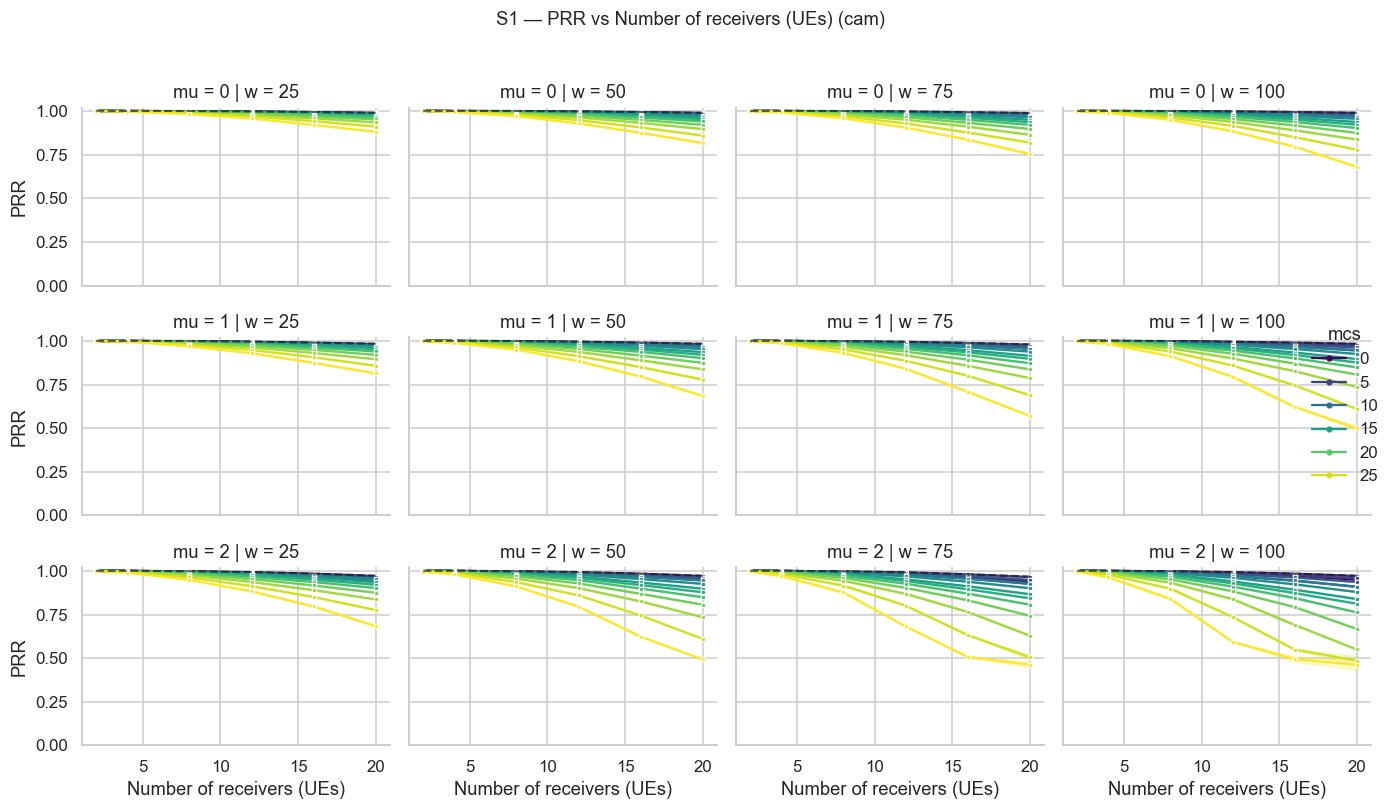

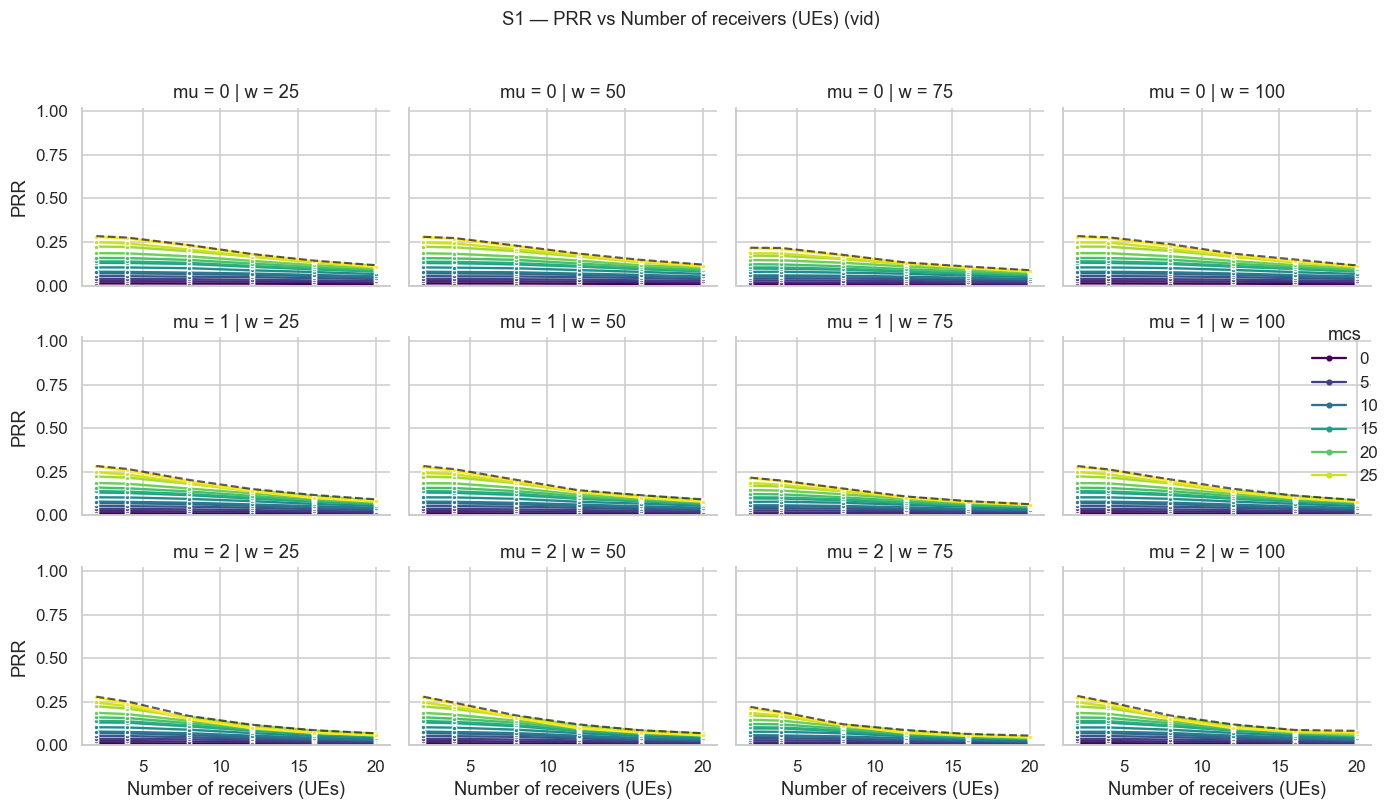

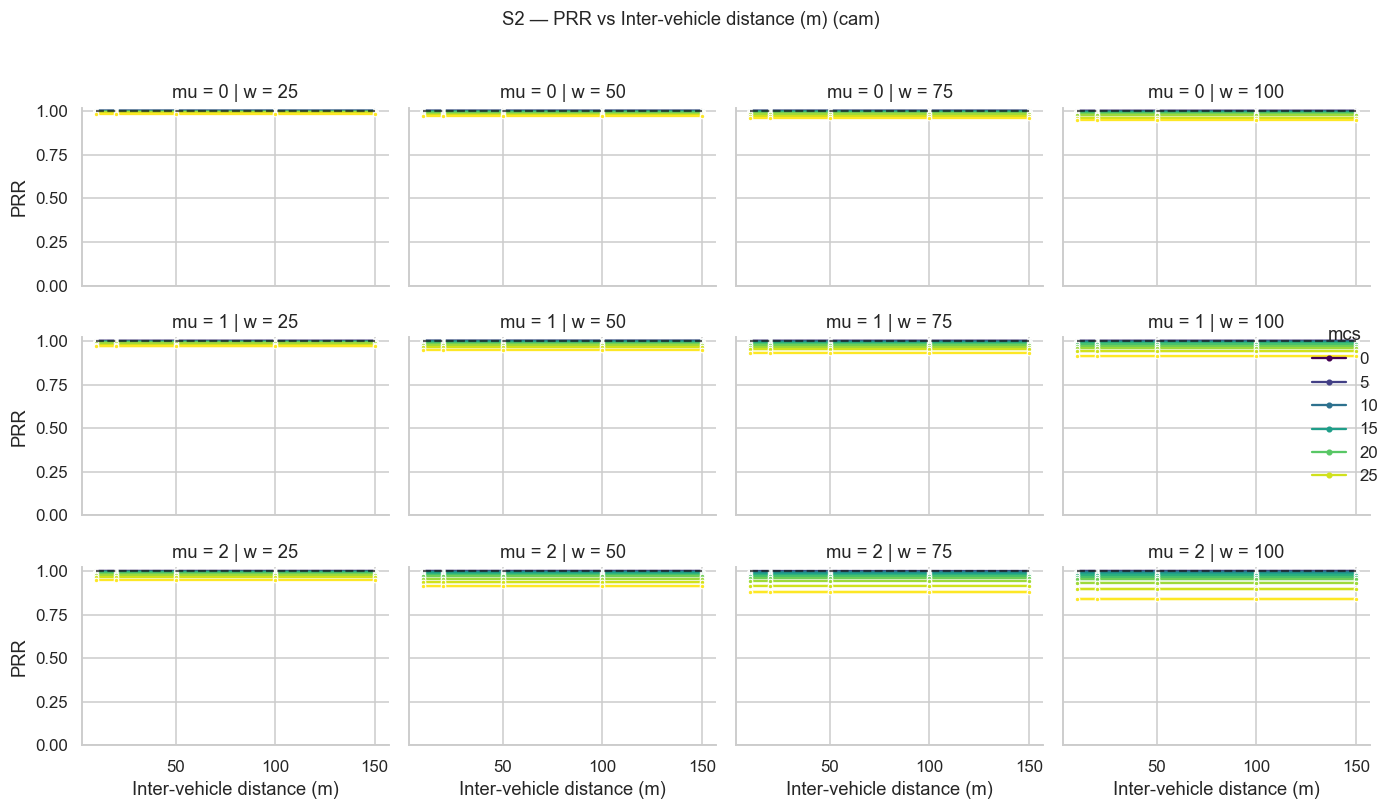

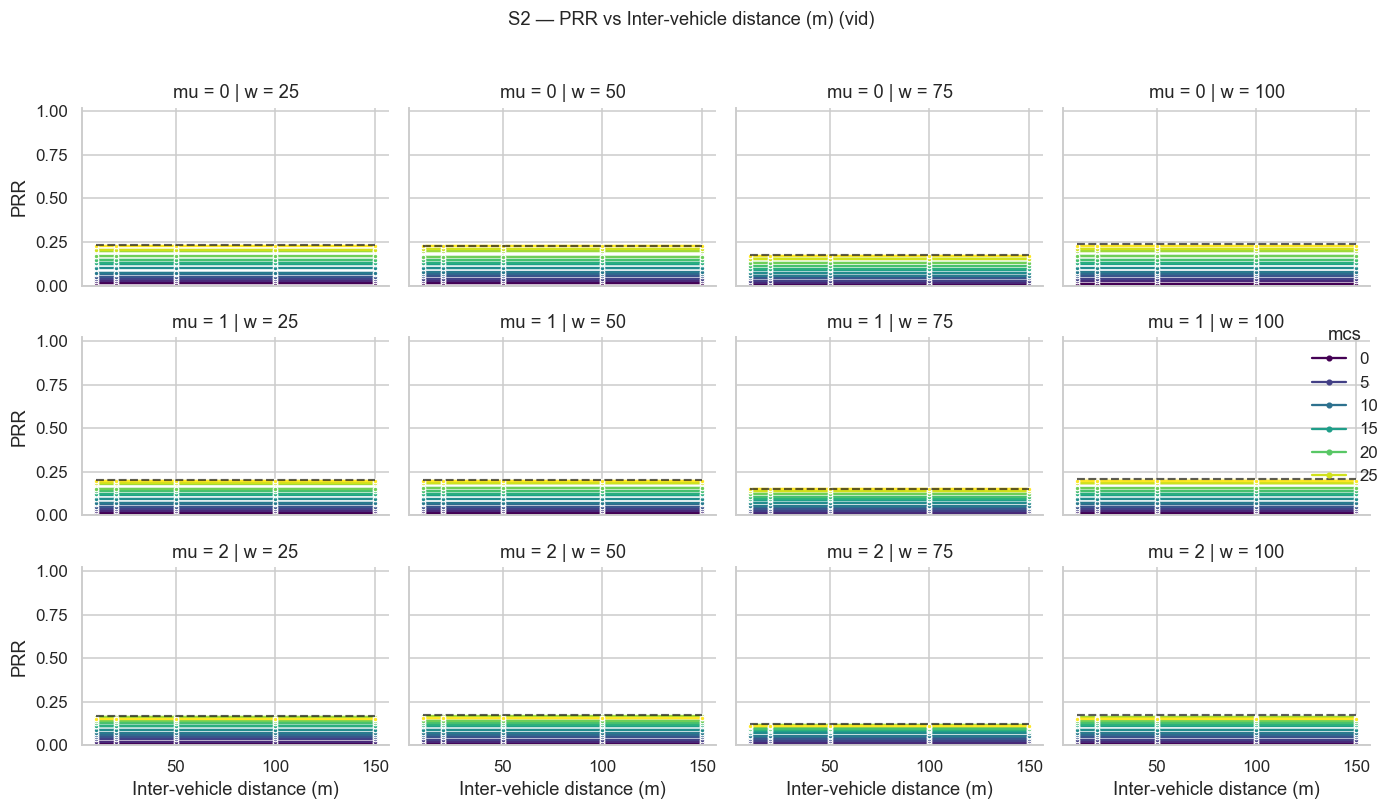

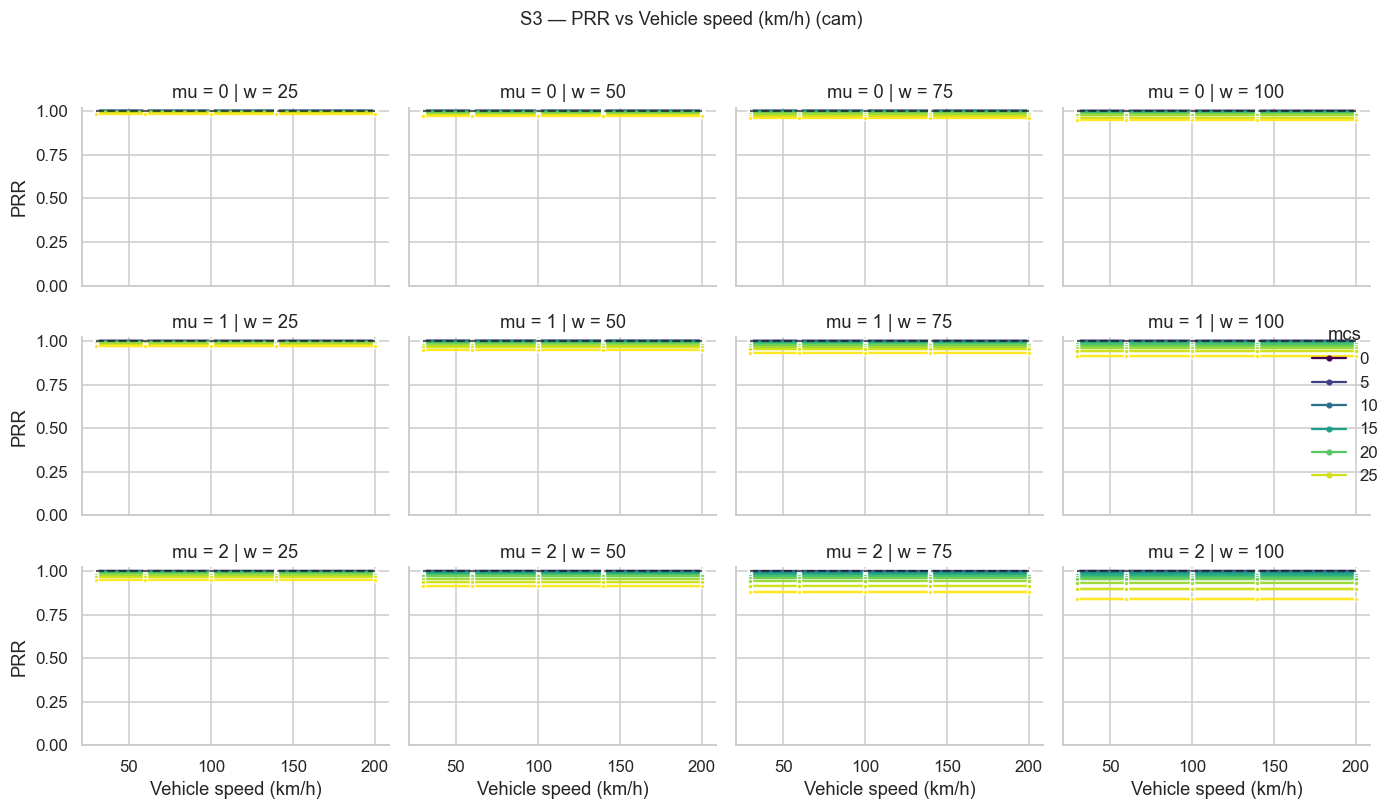

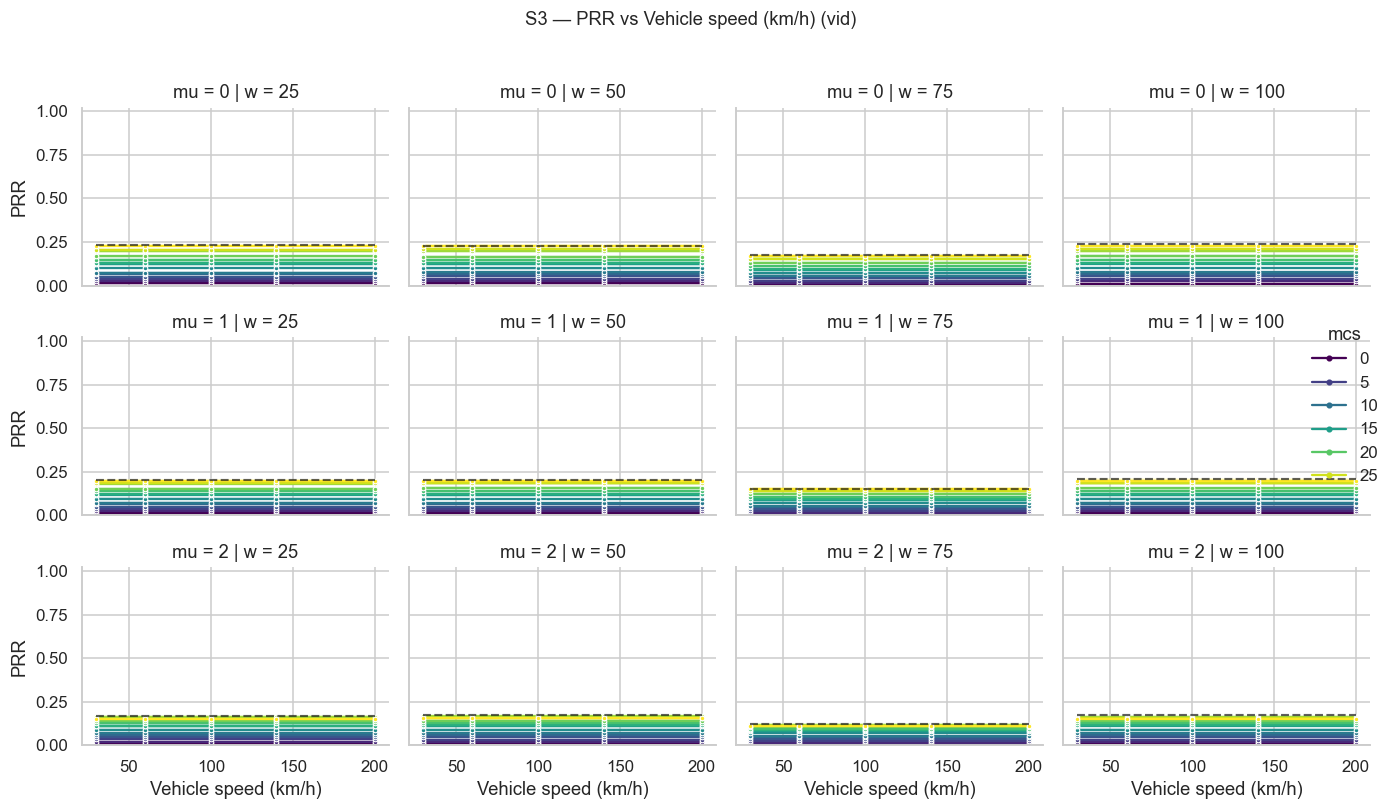

In [5]:
for scen in ('s1', 's2', 's3'):
    for flow in ('cam', 'vid'):
        facet_metric_vs_iter(df_run, scen, flow, 'prr', 'PRR',
            title=f'{scen.upper()} — PRR vs {SCEN_AXIS[scen][0]} ({flow})', ylim=(0, 1.02))

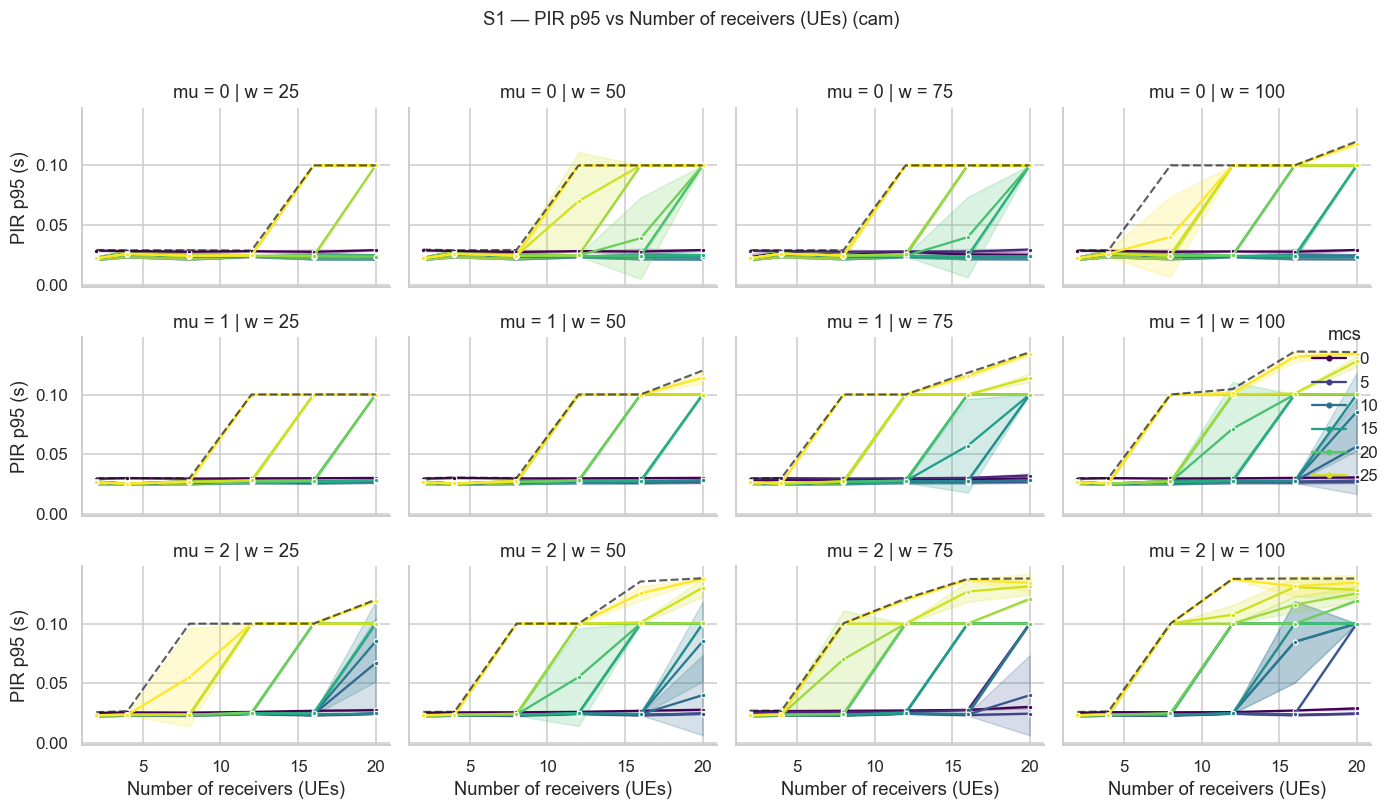

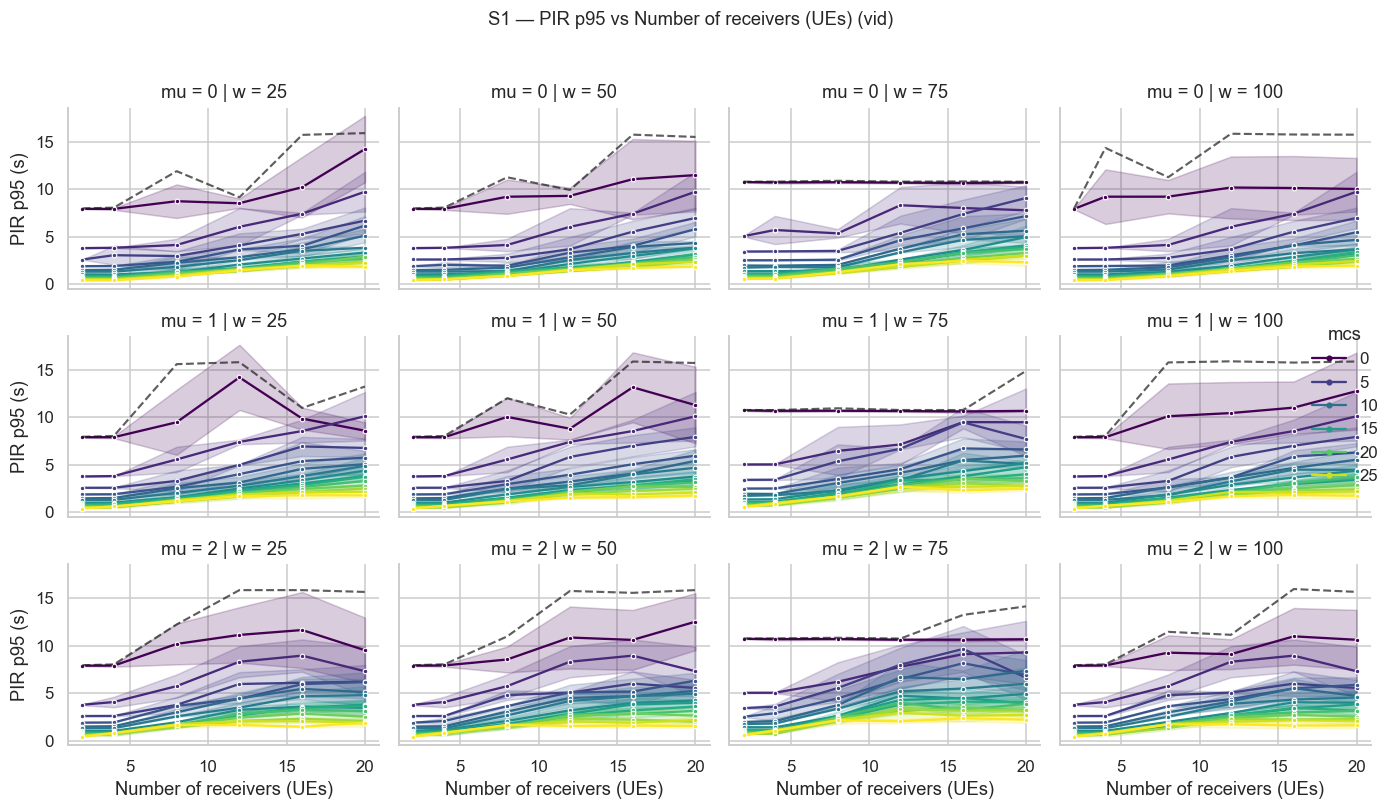

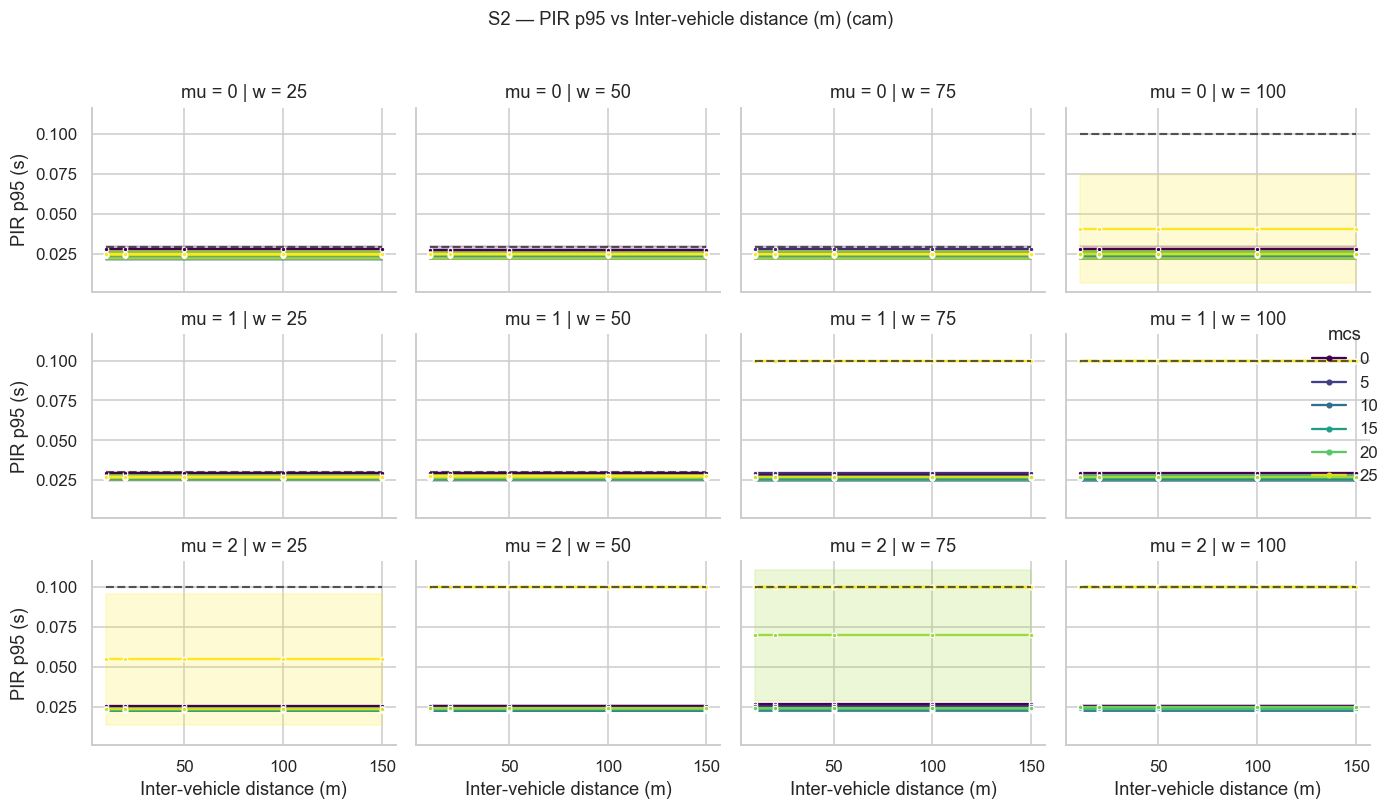

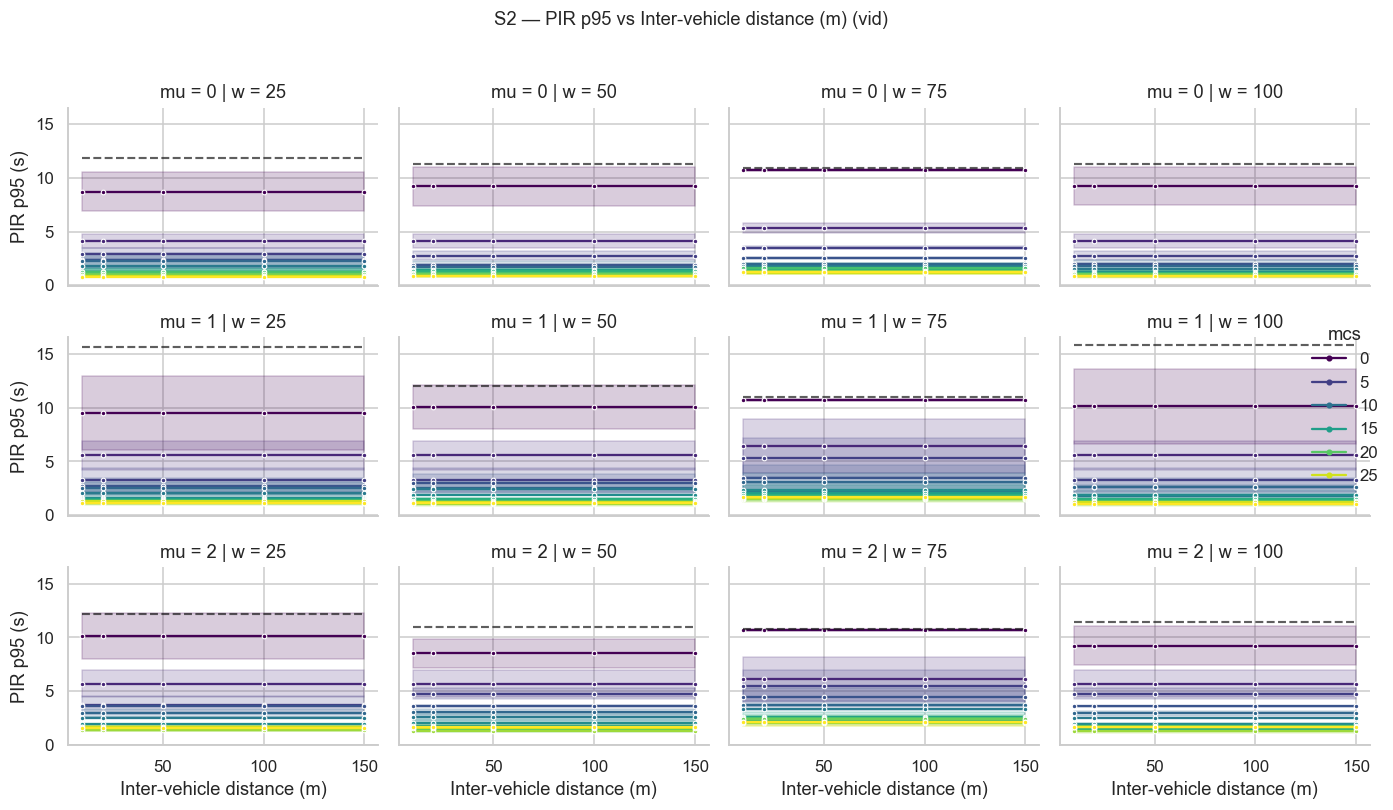

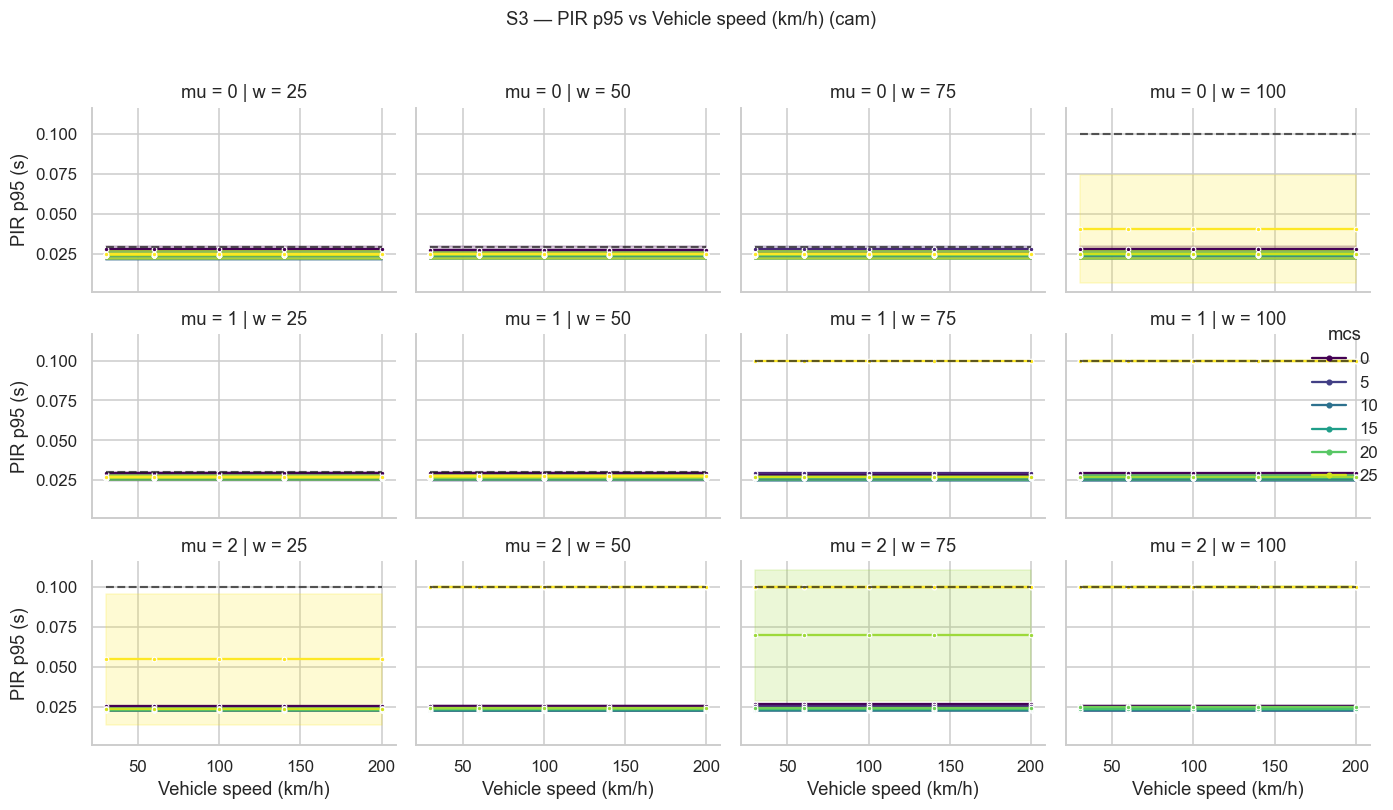

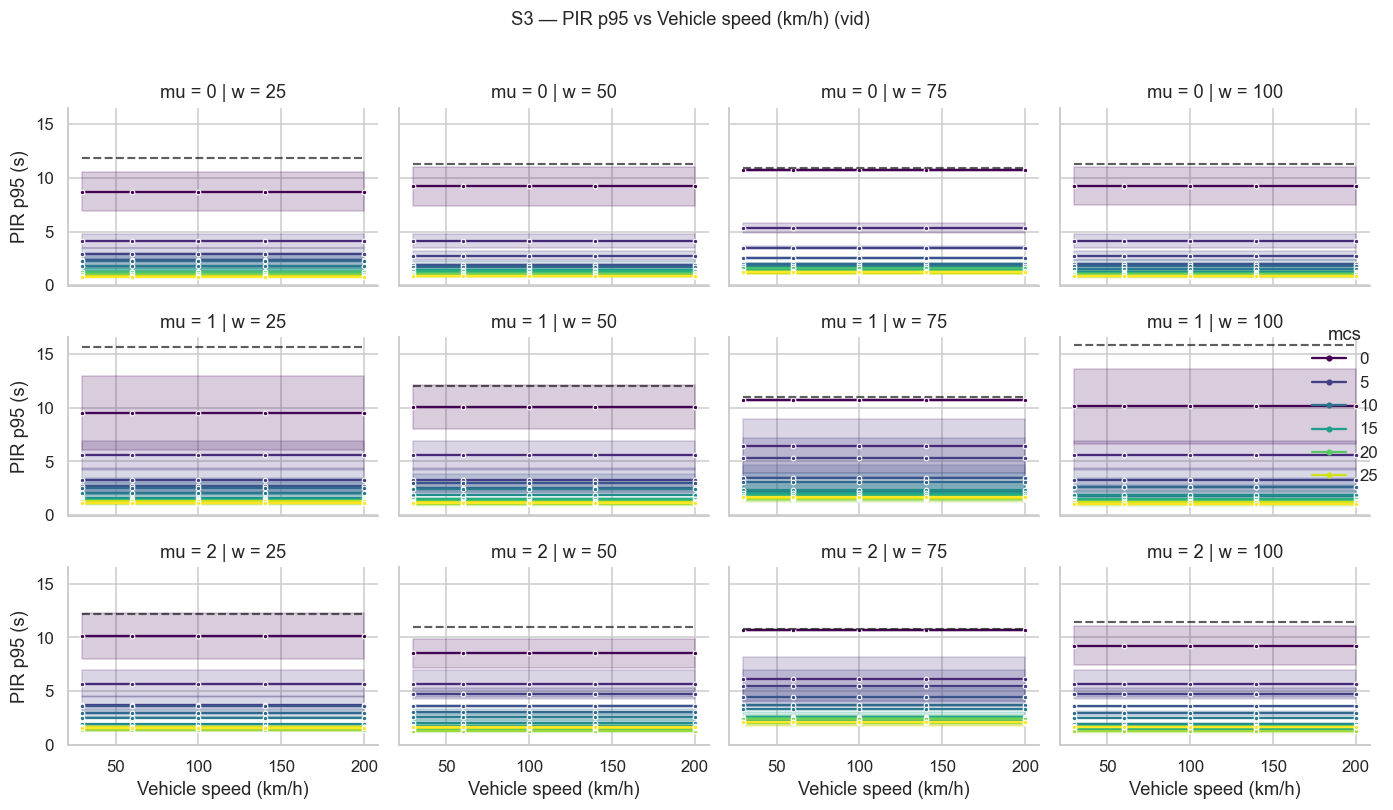

In [6]:
for scen in ('s1', 's2', 's3'):
    for flow in ('cam', 'vid'):
        facet_metric_vs_iter(df_run, scen, flow, 'pir_p95_s', 'PIR p95 (s)',
            title=f'{scen.upper()} — PIR p95 vs {SCEN_AXIS[scen][0]} ({flow})')

## §2 — Per-receiver best MCS: 1F (cam) vs 2F (vid)

For each (scenario, condition, μ, w, rx_node, seed) we pick the MCS that maximises `prr_rx`. Heatmaps show the median across receivers and seeds; companion scatter shows how reach-vs-rate trades off with distance.

In [7]:
def per_rx_best_mcs(df_rx):
    """Return df with one row per (scen, cond, mu, w, rx_node, seed, flow) giving the MCS that maximises prr_rx."""
    s = df_rx.copy()
    s['prr'] = s['prr'].fillna(-1)  # treat missing as worst
    s = s.sort_values('prr', ascending=False)
    keys = ['scen', 'cond', 'iter_value', 'mu', 'w', 'rx_node', 'seed', 'flow']
    return s.groupby(keys, as_index=False).first()[keys + ['mcs', 'prr', 'pir_p95_s', 'distance_m']]

best_rx = per_rx_best_mcs(df_rx)
print('per-rx best MCS rows:', len(best_rx))
best_rx.head()

per-rx best MCS rows: 15120


,scen,cond,iter_value,mu,w,rx_node,seed,flow,mcs,prr,pir_p95_s,distance_m
0,s1,nrx02,2,0,25,1,1,cam,0,1.000867,0.029000,20.0
1,s1,nrx02,2,0,25,1,1,vid,27,0.275000,0.400000,20.0
2,s1,nrx02,2,0,25,1,2,cam,0,1.000867,0.029000,20.0
3,s1,nrx02,2,0,25,1,2,vid,27,0.279167,0.400000,20.0
4,s1,nrx02,2,0,25,1,3,cam,0,1.000868,0.028214,20.0


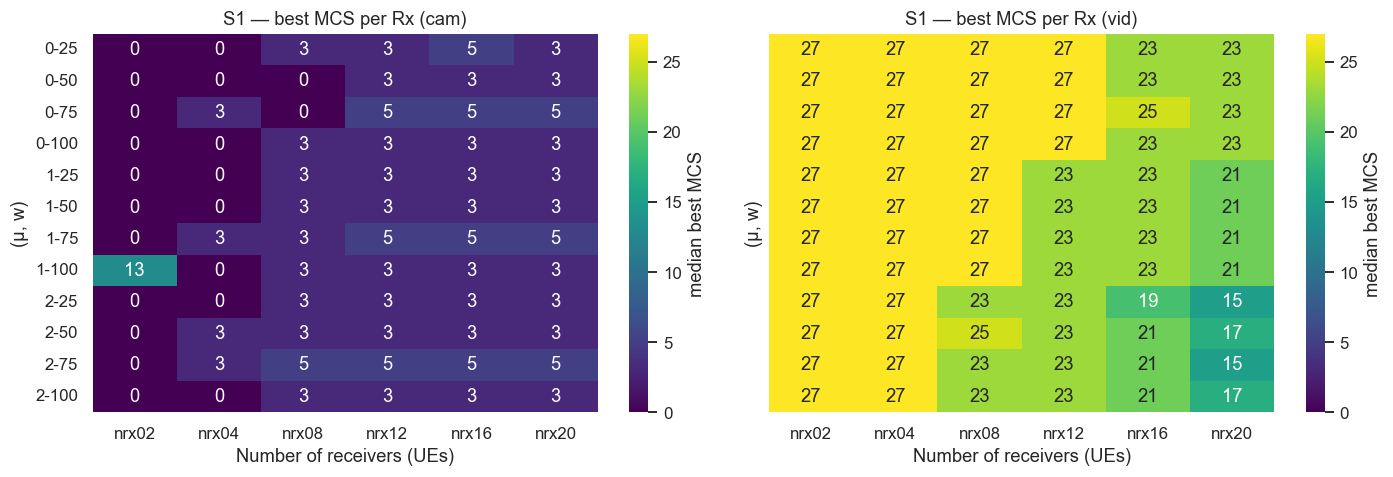

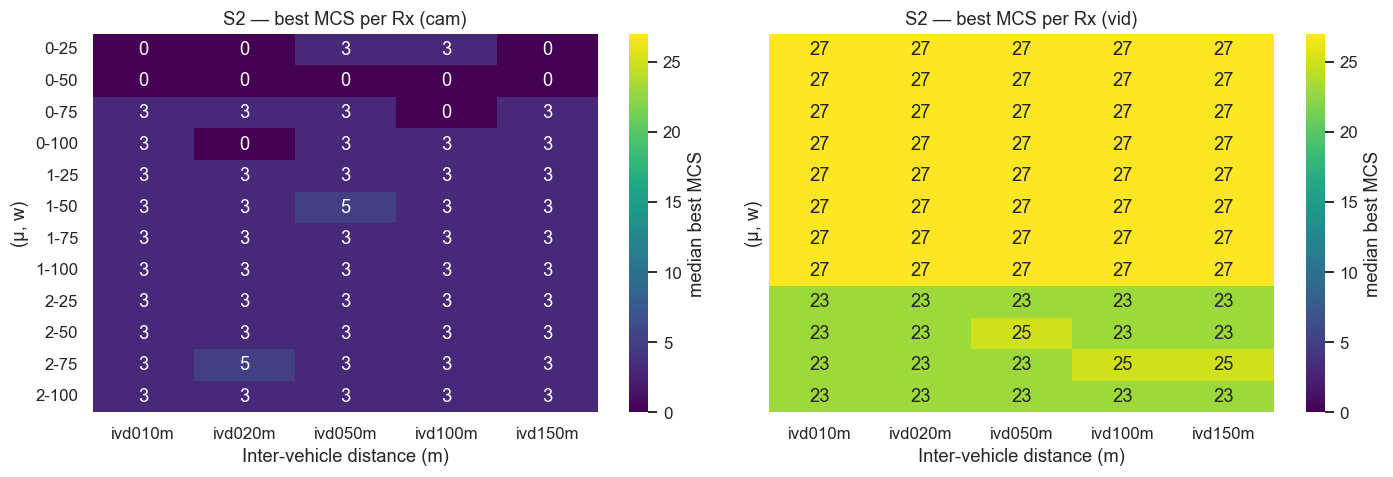

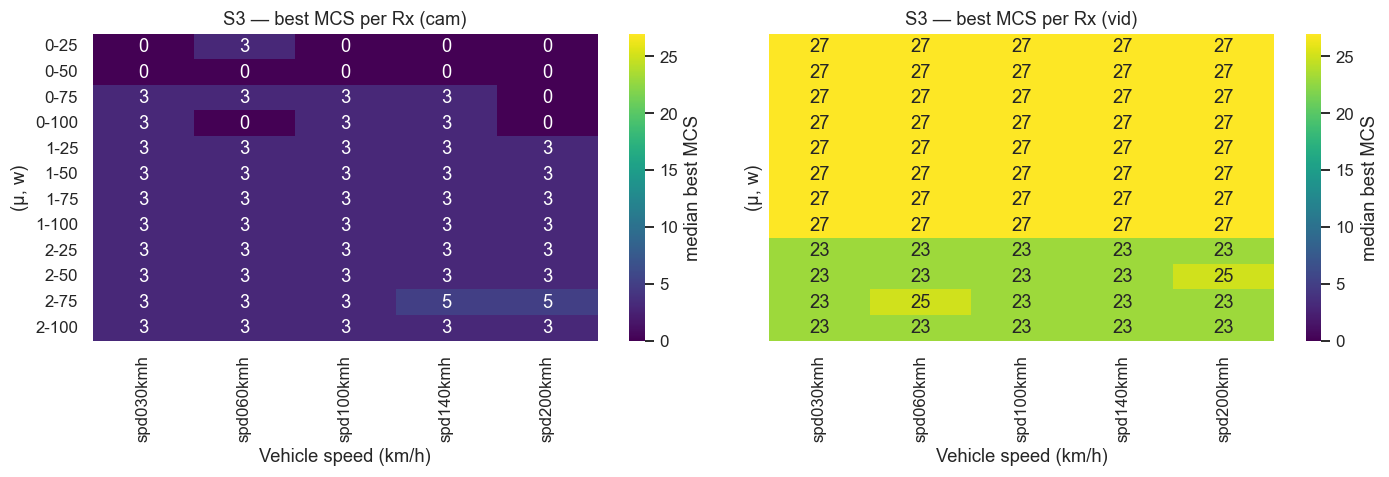

In [8]:
# Heatmap: median best-MCS across receivers and seeds, y=(mu, w), x=cond ordered by iter_value, one panel per (scenario, flow).
for scen in ('s1', 's2', 's3'):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
    for ax, flow in zip(axes, ('cam', 'vid')):
        sub = best_rx[(best_rx['scen']==scen) & (best_rx['flow']==flow)]
        if sub.empty:
            ax.set_title(f'{scen.upper()} {flow}: no data'); continue
        ord_conds = (sub.drop_duplicates('cond').sort_values('iter_value')['cond'].tolist())
        piv = (sub.groupby(['mu','w','cond'])['mcs'].median()
                  .unstack('cond').reindex(columns=ord_conds))
        sns.heatmap(piv, annot=True, fmt='.0f', cmap='viridis', vmin=0, vmax=27,
                    cbar_kws={'label':'median best MCS'}, ax=ax)
        ax.set_title(f'{scen.upper()} — best MCS per Rx ({flow})')
        ax.set_xlabel(SCEN_AXIS[scen][0]); ax.set_ylabel('(μ, w)')
    plt.tight_layout(); plt.show(); plt.close(fig)

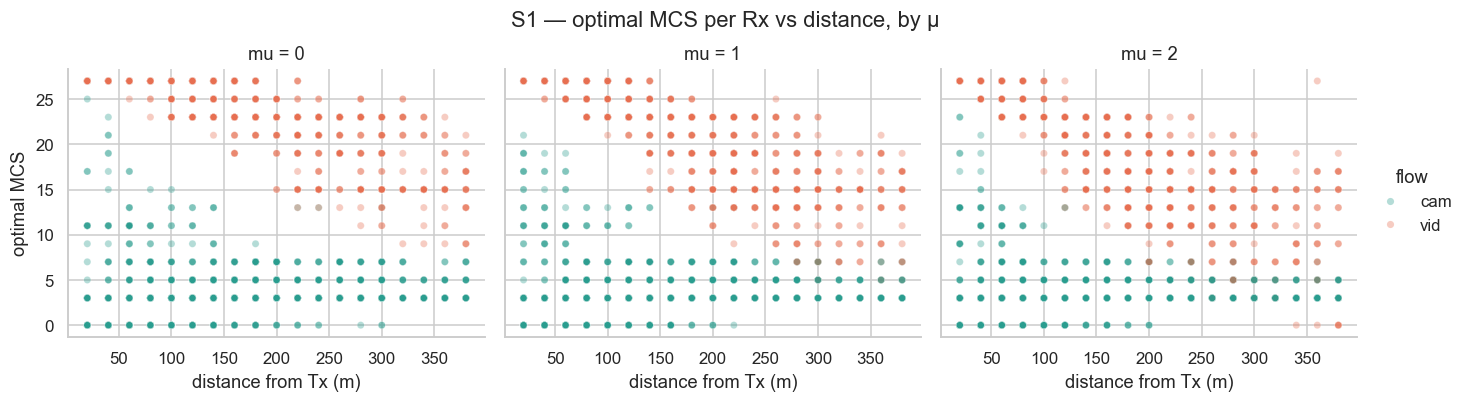

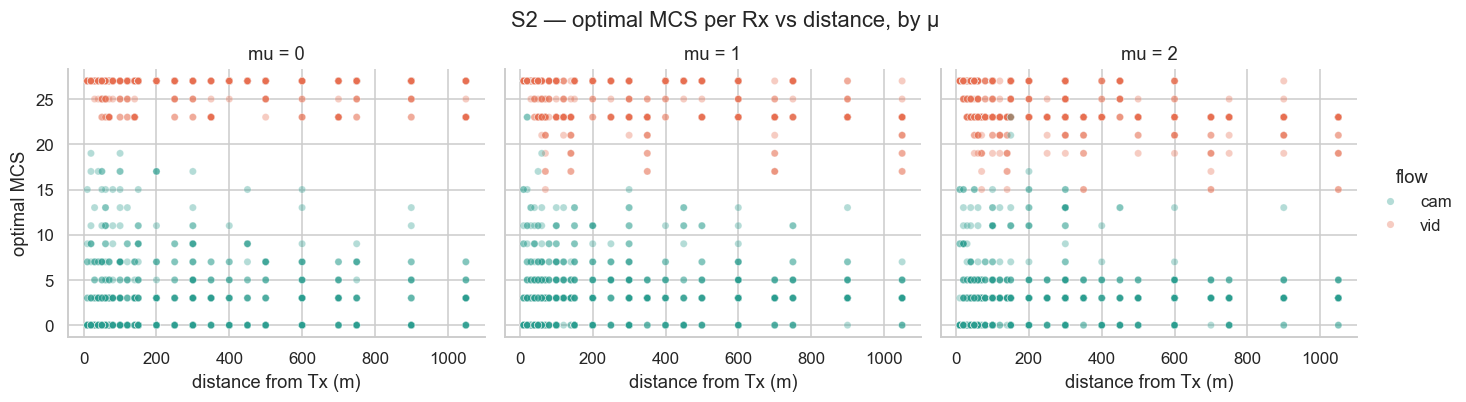

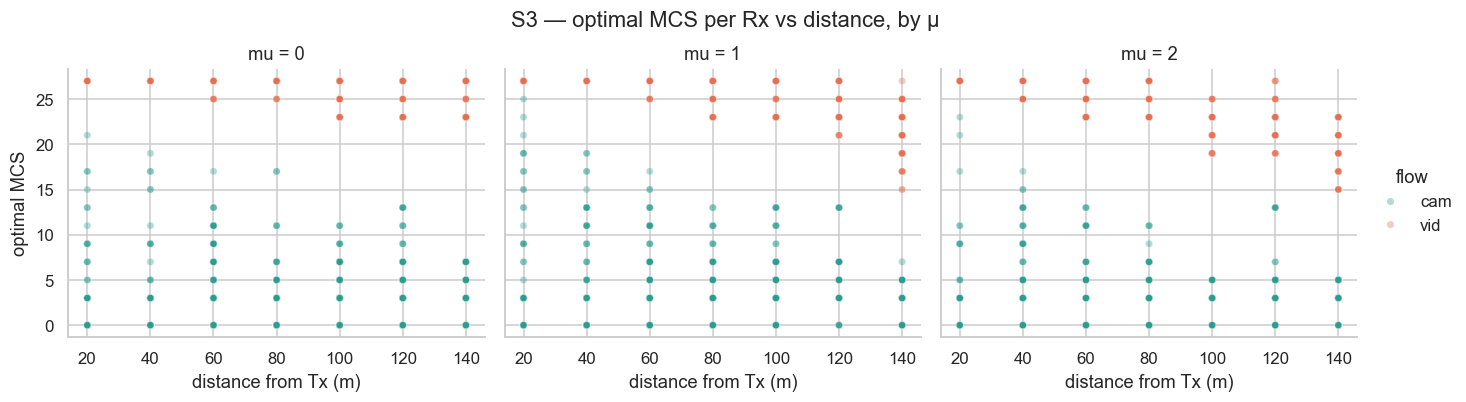

In [9]:
# Companion: scatter of optimal MCS vs distance from Tx, faceted by μ, hued by flow.
for scen in ('s1', 's2', 's3'):
    sub = best_rx[(best_rx['scen']==scen) & best_rx['distance_m'].notna()]
    if sub.empty: continue
    g = sns.relplot(data=sub, x='distance_m', y='mcs', hue='flow', col='mu',
                    kind='scatter', alpha=0.35, s=22, height=3.5, aspect=1.2,
                    palette={'cam':'#2a9d8f', 'vid':'#e76f51'})
    g.set_axis_labels('distance from Tx (m)', 'optimal MCS')
    g.figure.suptitle(f'{scen.upper()} — optimal MCS per Rx vs distance, by μ', y=1.04)
    plt.show(); plt.close(g.figure)

In [10]:
# Side-by-side table per scenario: cond | flow | median_best_mcs | mean_achieved_prr | mean_pir_p95
for scen in ('s1', 's2', 's3'):
    sub = best_rx[best_rx['scen']==scen]
    if sub.empty: continue
    tab = (sub.groupby(['cond','flow','iter_value'])
             .agg(median_best_mcs=('mcs','median'),
                  mean_achieved_prr=('prr','mean'),
                  mean_pir_p95_s=('pir_p95_s','mean'))
             .reset_index().sort_values(['iter_value','flow']))
    print(f'\n=== {scen.upper()} — best MCS per Rx (median across rx_nodes & seeds) ===')
    print(tab.to_string(index=False))


=== S1 — best MCS per Rx (median across rx_nodes & seeds) ===
 cond flow  iter_value  median_best_mcs  mean_achieved_prr  mean_pir_p95_s
nrx02  cam           2              0.0           1.000752        0.027181
nrx02  vid           2             27.0           0.262153        0.440413
nrx04  cam           4              0.0           1.000612        0.027199
nrx04  vid           4             27.0           0.242083        0.639711
nrx08  cam           8              3.0           0.999272        0.026112
nrx08  vid           8             27.0           0.190972        1.126753
nrx12  cam          12              3.0           0.995379        0.025987
nrx12  vid          12             23.0           0.148277        1.973594
nrx16  cam          16              3.0           0.989326        0.027801
nrx16  vid          16             23.0           0.119384        2.978070
nrx20  cam          20              3.0           0.980614        0.036250
nrx20  vid          20             21

## §3 — Optimal MCS at each (μ, w) per scenario iteration

For every (scenario, condition, μ, w), find the MCS that maximises mean PRR (over seeds and receivers) for each flow. Δ = vid − cam shows how the optimum shifts when the second flow appears.

In [11]:
def optimal_mcs_table(df_run):
    """For each (scen, cond, mu, w, flow) return the MCS maximising mean(prr) across seeds."""
    base = (df_run.groupby(['scen','cond','iter_value','mu','w','flow','mcs'])['prr']
                  .mean().reset_index())
    base = base.sort_values('prr', ascending=False)
    keys = ['scen','cond','iter_value','mu','w','flow']
    return base.groupby(keys, as_index=False).first()[keys + ['mcs','prr']]

opt = optimal_mcs_table(df_run)
print('optimal-MCS rows:', len(opt))
opt.head()

optimal-MCS rows: 384


,scen,cond,iter_value,mu,w,flow,mcs,prr
0,s1,nrx02,2,0,25,cam,0,1.001042
1,s1,nrx02,2,0,25,vid,27,0.279167
2,s1,nrx02,2,0,50,cam,0,1.001042
3,s1,nrx02,2,0,50,vid,27,0.278333
4,s1,nrx02,2,0,75,cam,0,1.000868


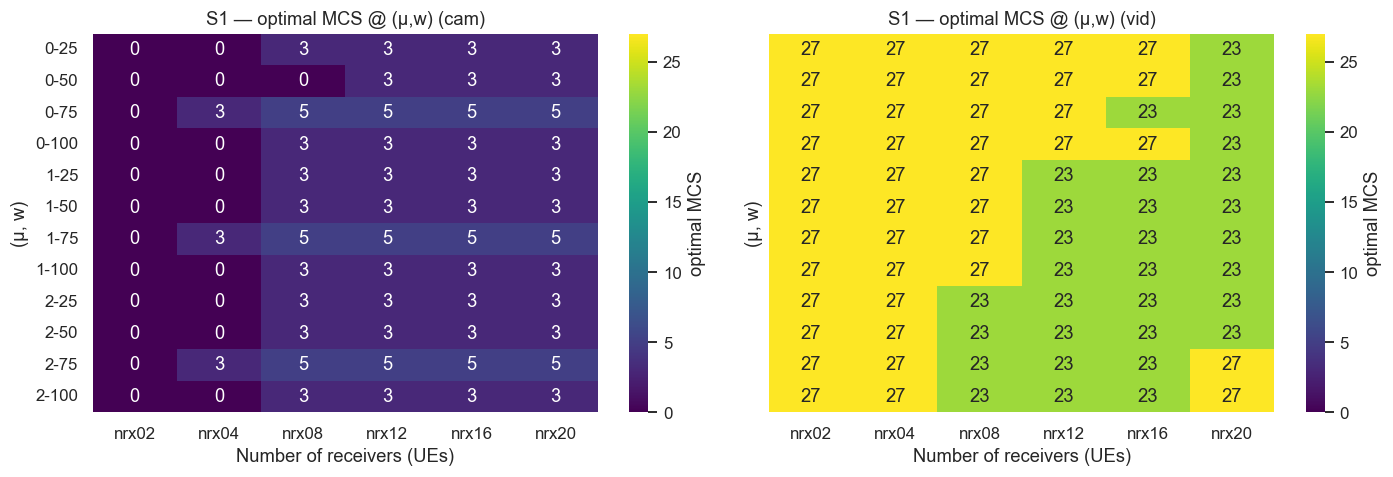

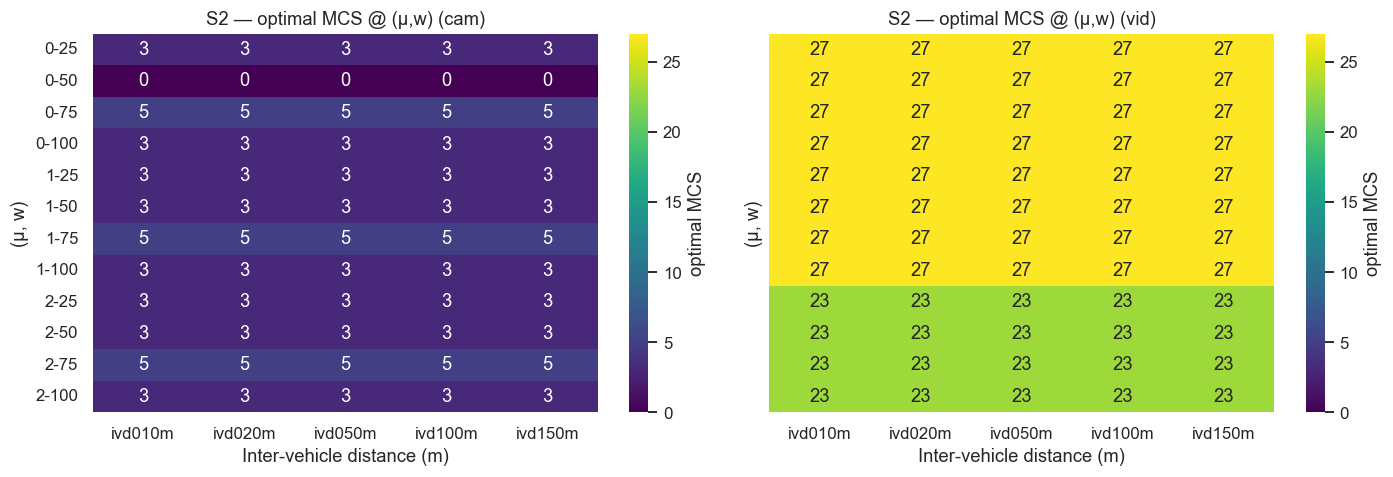

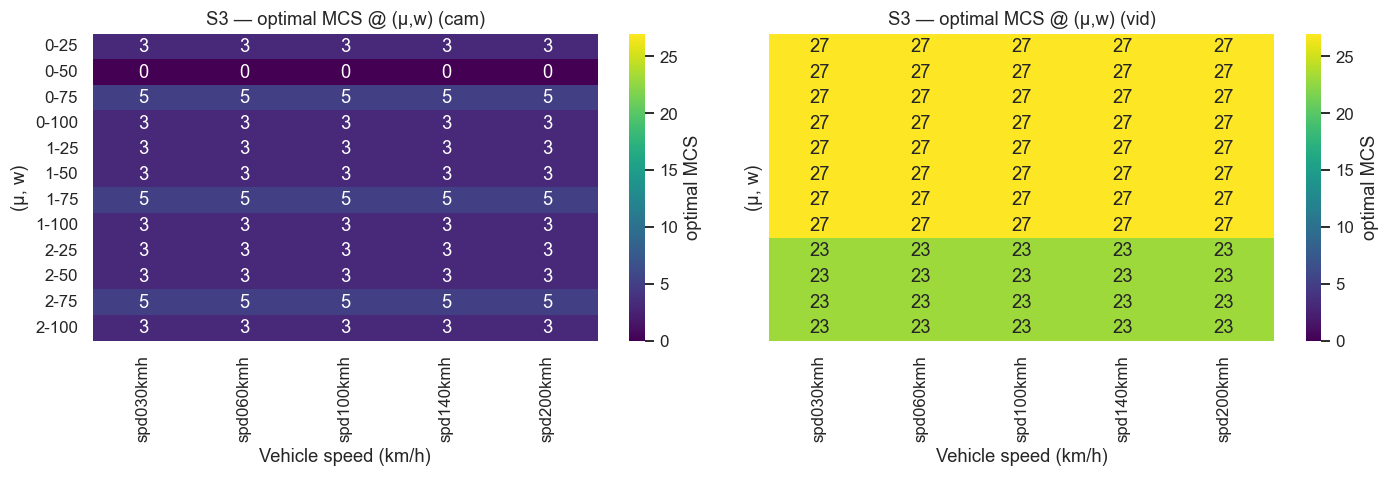

In [12]:
for scen in ('s1', 's2', 's3'):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
    for ax, flow in zip(axes, ('cam', 'vid')):
        sub = opt[(opt['scen']==scen) & (opt['flow']==flow)]
        ord_conds = sub.drop_duplicates('cond').sort_values('iter_value')['cond'].tolist()
        piv = sub.pivot_table(index=['mu','w'], columns='cond', values='mcs').reindex(columns=ord_conds)
        sns.heatmap(piv, annot=True, fmt='.0f', cmap='viridis', vmin=0, vmax=27,
                    cbar_kws={'label':'optimal MCS'}, ax=ax)
        ax.set_title(f'{scen.upper()} — optimal MCS @ (μ,w) ({flow})')
        ax.set_xlabel(SCEN_AXIS[scen][0]); ax.set_ylabel('(μ, w)')
    plt.tight_layout(); plt.show(); plt.close(fig)

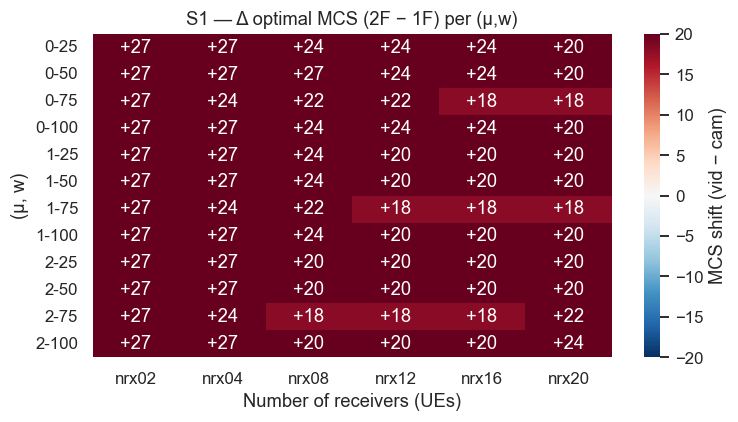

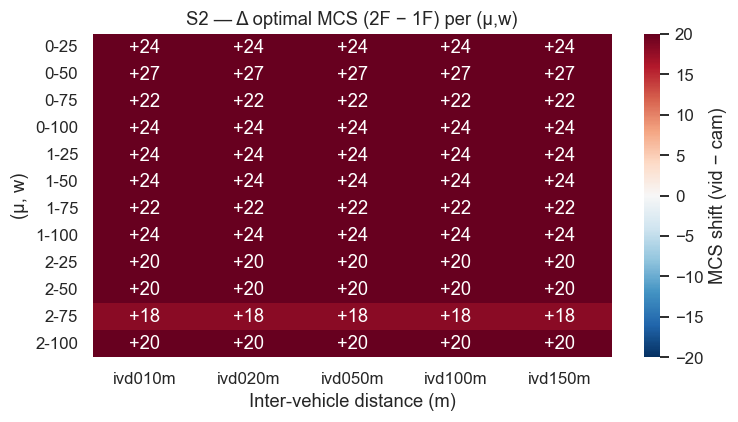

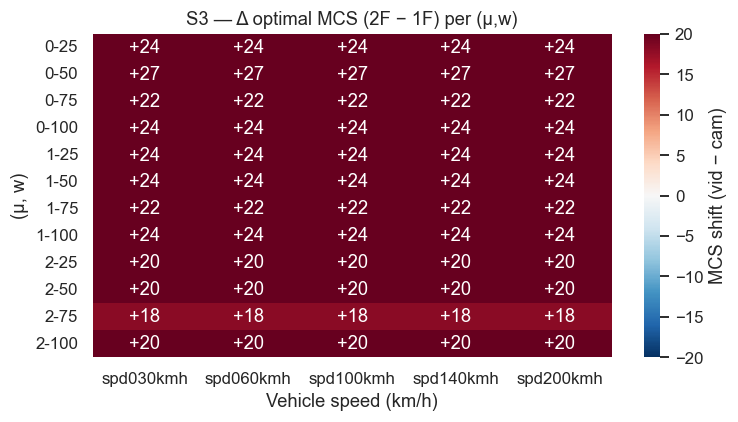

In [13]:
# Δ = optimal_2F (vid) − optimal_1F (cam) per (scen, cond, mu, w)
wide = opt.pivot_table(index=['scen','cond','iter_value','mu','w'], columns='flow', values='mcs').reset_index()
wide['delta_vid_minus_cam'] = wide['vid'] - wide['cam']
for scen in ('s1', 's2', 's3'):
    sub = wide[wide['scen']==scen]
    if sub.empty: continue
    ord_conds = sub.drop_duplicates('cond').sort_values('iter_value')['cond'].tolist()
    piv = sub.pivot_table(index=['mu','w'], columns='cond', values='delta_vid_minus_cam').reindex(columns=ord_conds)
    fig, ax = plt.subplots(figsize=(7, 4))
    sns.heatmap(piv, annot=True, fmt='+.0f', center=0, cmap='RdBu_r', vmin=-20, vmax=20,
                cbar_kws={'label':'MCS shift (vid − cam)'}, ax=ax)
    ax.set_title(f'{scen.upper()} — Δ optimal MCS (2F − 1F) per (μ,w)')
    ax.set_xlabel(SCEN_AXIS[scen][0]); ax.set_ylabel('(μ, w)')
    plt.tight_layout(); plt.show(); plt.close(fig)

## §4 — PRR & PIR variation with flow traffic, per (μ, w, MCS)

x = MCS, y = PRR (and PIR_p95), hue = flow. Aggregated across all scenario iterations to expose the link-quality-vs-rate curve per PHY config and how the heavier video flow shifts it.

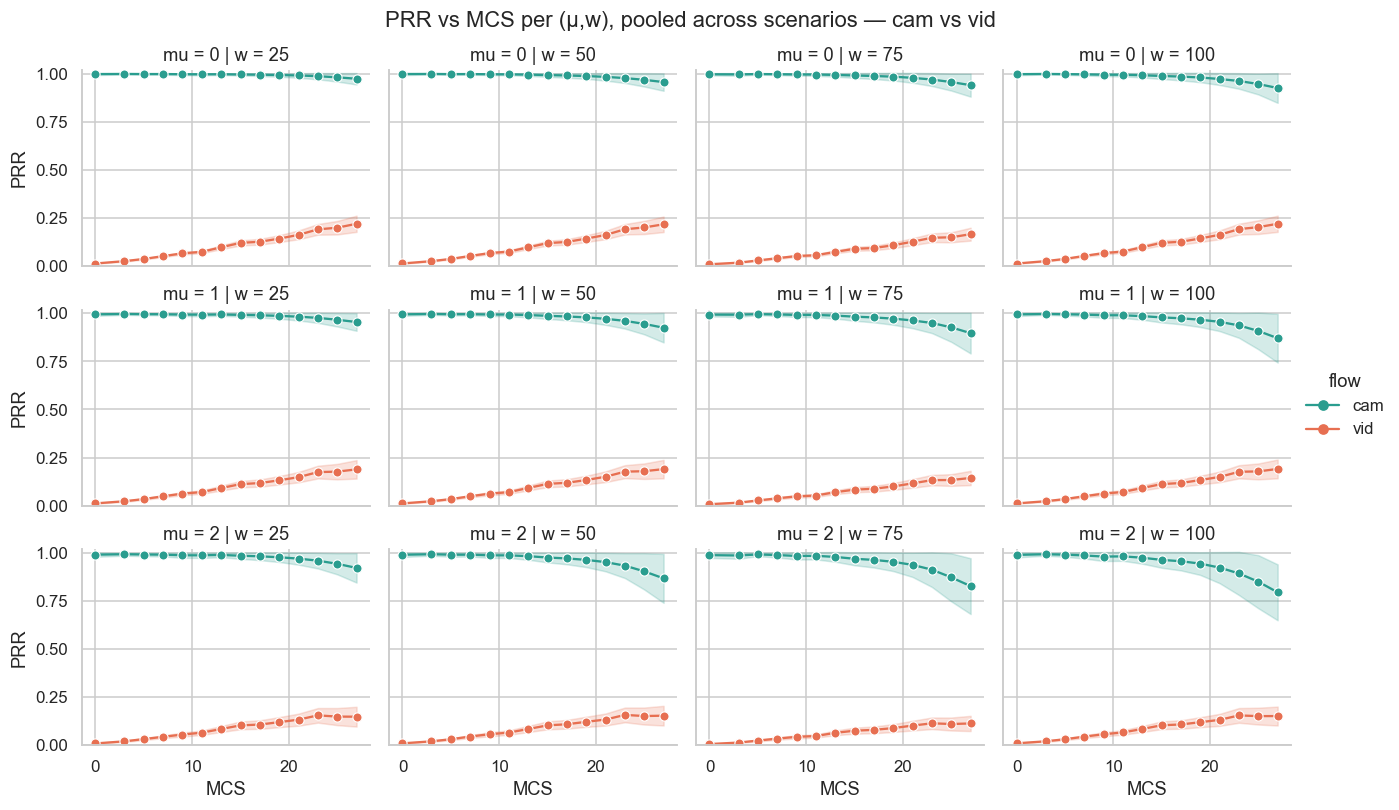

In [14]:
g = sns.relplot(data=df_run, x='mcs', y='prr', hue='flow', row='mu', col='w',
                kind='line', estimator='mean', errorbar='sd', marker='o',
                palette={'cam':'#2a9d8f', 'vid':'#e76f51'},
                height=2.4, aspect=1.25)
for ax in g.axes.flat: ax.set_ylim(0, 1.02)
g.figure.suptitle('PRR vs MCS per (μ,w), pooled across scenarios — cam vs vid', y=1.02)
g.set_axis_labels('MCS', 'PRR'); plt.show(); plt.close(g.figure)

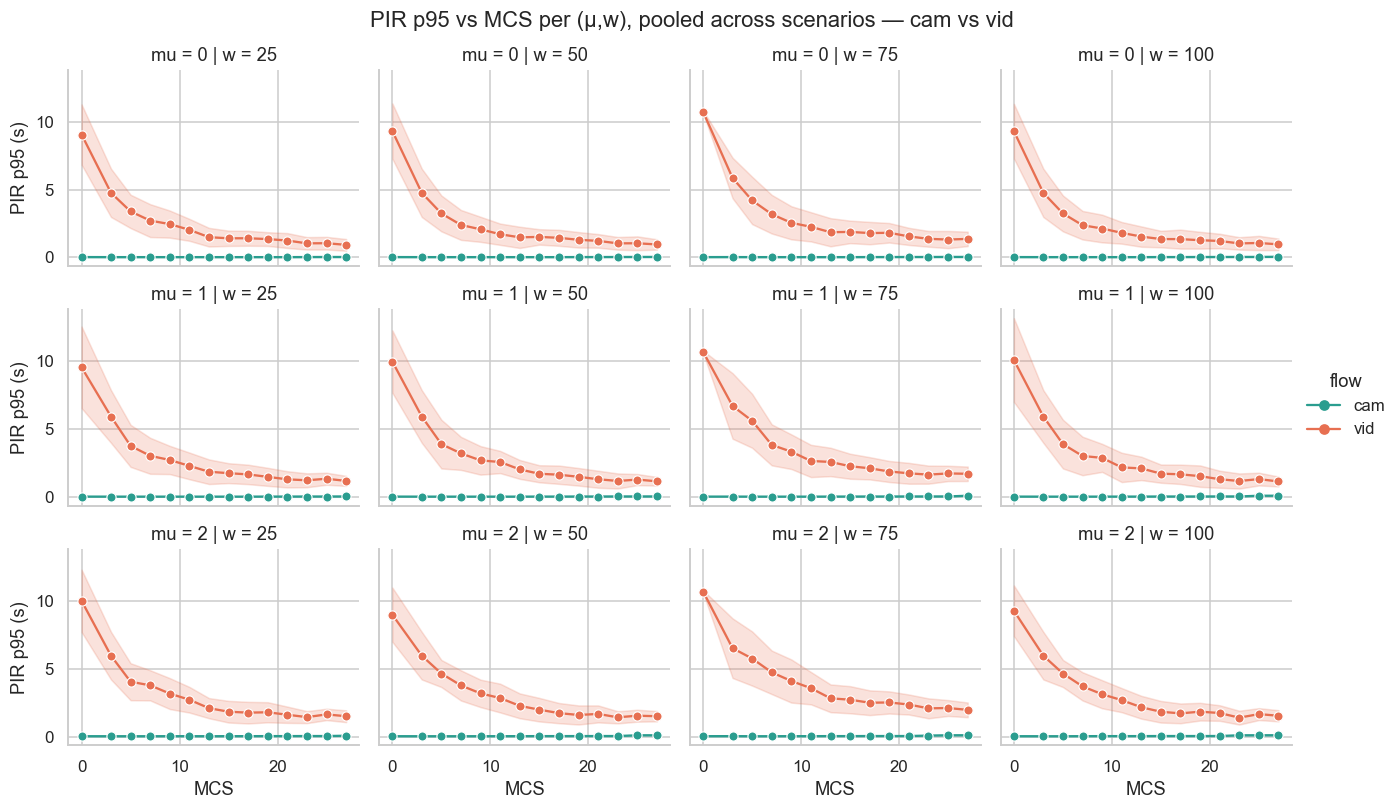

In [15]:
g = sns.relplot(data=df_run, x='mcs', y='pir_p95_s', hue='flow', row='mu', col='w',
                kind='line', estimator='mean', errorbar='sd', marker='o',
                palette={'cam':'#2a9d8f', 'vid':'#e76f51'},
                height=2.4, aspect=1.25)
g.figure.suptitle('PIR p95 vs MCS per (μ,w), pooled across scenarios — cam vs vid', y=1.02)
g.set_axis_labels('MCS', 'PIR p95 (s)'); plt.show(); plt.close(g.figure)

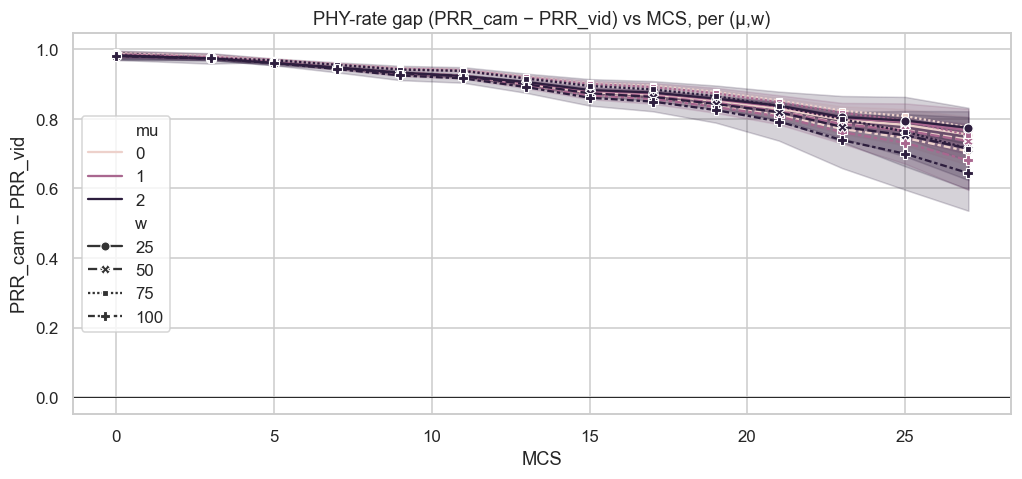

In [16]:
# PHY-rate gap: prr_cam − prr_vid per (μ, w, mcs)
wide_prr = (df_run.groupby(['scen','cond','iter_value','mu','w','mcs','flow'])['prr']
                  .mean().unstack('flow').reset_index().dropna(subset=['cam','vid']))
wide_prr['gap'] = wide_prr['cam'] - wide_prr['vid']
fig, ax = plt.subplots(figsize=(11, 4.5))
sns.lineplot(data=wide_prr, x='mcs', y='gap', hue='mu', style='w',
             estimator='mean', errorbar='sd', markers=True, ax=ax)
ax.axhline(0, color='k', lw=0.6)
ax.set_title('PHY-rate gap (PRR_cam − PRR_vid) vs MCS, per (μ,w)')
ax.set_xlabel('MCS'); ax.set_ylabel('PRR_cam − PRR_vid')
plt.show(); plt.close(fig)

## §5 — Optimal (μ, w, MCS) leaderboards: 1F vs 2F vs joint-min

In [17]:
phy_agg = (df_run.groupby(['mu','w','mcs','flow'])
                 .agg(prr=('prr','mean'),
                      pir_p95=('pir_p95_s','mean'),
                      coll=('coll_rate','mean'),
                      nack_rate=('harq_nack_rate','mean'),
                      tput=('throughput_kbps','mean'),
                      n=('prr','size'))
                 .reset_index())
wide_phy = phy_agg.pivot_table(index=['mu','w','mcs'], columns='flow',
                                values=['prr','pir_p95','coll','nack_rate','tput'])
wide_phy.columns = [f'{a}_{b}' for a,b in wide_phy.columns]
wide_phy = wide_phy.reset_index()
wide_phy['min_prr'] = wide_phy[['prr_cam','prr_vid']].min(axis=1)

def show_top(label, sort_col, ascending=False, n=10):
    cols = ['mu','w','mcs','prr_cam','prr_vid','min_prr',
            'pir_p95_cam','pir_p95_vid','coll_cam','nack_rate_cam','tput_cam','tput_vid']
    print(f'\n=== Top-{n} by {label} ===')
    print(wide_phy.sort_values(sort_col, ascending=ascending)[cols].head(n).to_string(index=False))

show_top('1F-optimal (PRR cam)', 'prr_cam')
show_top('2F-optimal (PRR vid)', 'prr_vid')
show_top('Joint-min PRR (worst-flow)', 'min_prr')


=== Top-10 by 1F-optimal (PRR cam) ===
 mu   w  mcs  prr_cam  prr_vid  min_prr  pir_p95_cam  pir_p95_vid  coll_cam  nack_rate_cam    tput_cam   tput_vid
  0 100    3 0.998229 0.023578 0.023578     0.024083     4.757232       0.0       0.000684 1507.000000 356.354167
  0  25    3 0.998229 0.023578 0.023578     0.024083     4.757232       0.0       0.000684 1507.000000 356.354167
  0  50    3 0.998229 0.023578 0.023578     0.024083     4.757232       0.0       0.000684 1507.000000 356.354167
  0  75    5 0.997830 0.027074 0.027074     0.024083     4.197268       0.0       0.001333 1506.125000 406.145833
  0  25    7 0.997712 0.049711 0.049711     0.024088     2.711892       0.0       0.002005 1505.795833 751.666667
  0  25    5 0.997664 0.034998 0.034998     0.023995     3.389200       0.0       0.001406 1505.879167 527.500000
  0  50    0 0.997620 0.011425 0.011425     0.027808     9.303659       0.0       0.000043 1504.137500 170.416667
  0  50    7 0.997612 0.050651 0.050651     0.02

In [18]:
# Same leaderboard per scenario (in case s1/s2/s3 prefer different PHYs).
for scen in ('s1', 's2', 's3'):
    sub = df_run[df_run['scen']==scen]
    if sub.empty: continue
    a = (sub.groupby(['mu','w','mcs','flow'])['prr'].mean().unstack('flow')).dropna(subset=['cam','vid'])
    a['min_prr'] = a[['cam','vid']].min(axis=1)
    a = a.sort_values('min_prr', ascending=False).head(5).reset_index()
    print(f'\n=== {scen.upper()} — top-5 PHY (by joint-min PRR) ===')
    print(a.round(3).to_string(index=False))


=== S1 — top-5 PHY (by joint-min PRR) ===
 mu   w  mcs   cam   vid  min_prr
  0 100   27 0.883 0.201    0.201
  0  25   27 0.957 0.200    0.200
  0  50   27 0.931 0.200    0.200
  0 100   25 0.917 0.185    0.185
  0  50   25 0.948 0.184    0.184

=== S2 — top-5 PHY (by joint-min PRR) ===
 mu   w  mcs   cam   vid  min_prr
  0  25   27 0.983 0.229    0.229
  0 100   27 0.950 0.229    0.229
  0  50   27 0.971 0.225    0.225
  0 100   25 0.963 0.210    0.210
  0  50   25 0.979 0.208    0.208

=== S3 — top-5 PHY (by joint-min PRR) ===
 mu   w  mcs   cam   vid  min_prr
  0  25   27 0.983 0.229    0.229
  0 100   27 0.950 0.229    0.229
  0  50   27 0.971 0.225    0.225
  0 100   25 0.963 0.210    0.210
  0  50   25 0.979 0.208    0.208


## §6 — Bonus analyses

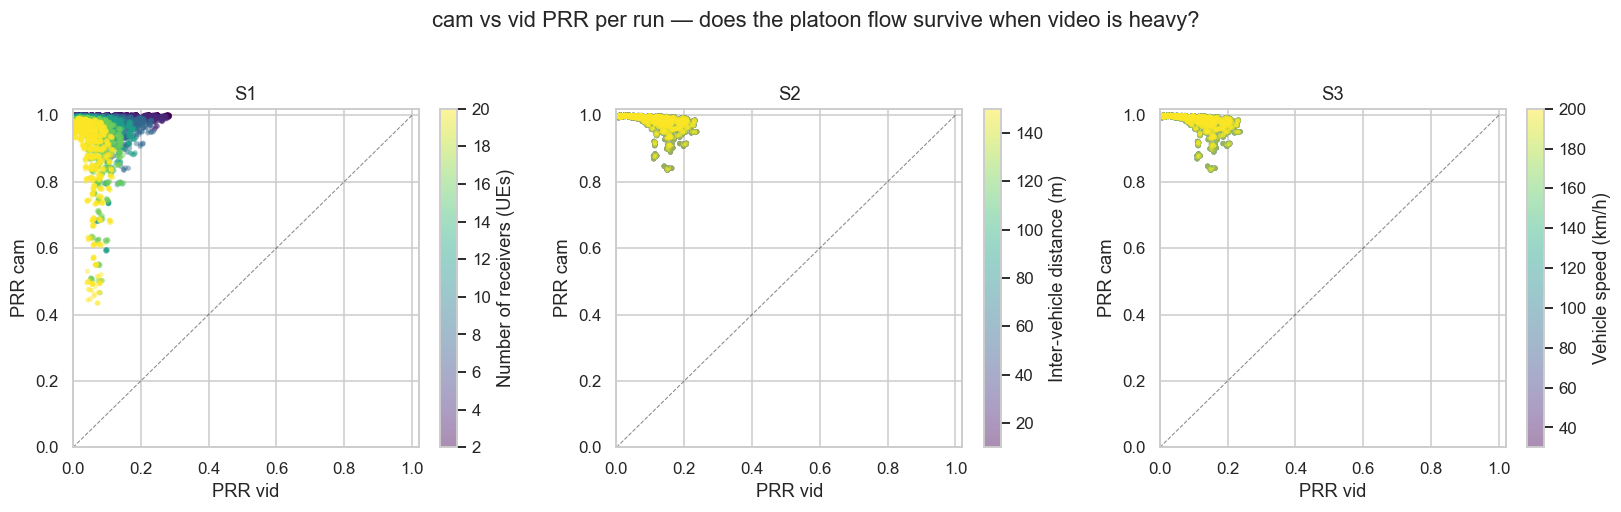

In [19]:
# 6a — cam degradation vs vid load: scatter prr_cam vs prr_vid, hued by scenario iteration value.
wide_per_run = (df_run.pivot_table(index=['stem','scen','cond','iter_value','mu','w','mcs','seed'],
                                    columns='flow', values='prr')
                       .reset_index().dropna(subset=['cam','vid']))
wide_per_run = wide_per_run.rename(columns={'cam':'prr_cam','vid':'prr_vid'})
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, scen in zip(axes, ('s1','s2','s3')):
    sub = wide_per_run[wide_per_run['scen']==scen]
    sc = ax.scatter(sub['prr_vid'], sub['prr_cam'], c=sub['iter_value'],
                    cmap='viridis', alpha=0.45, s=12, edgecolors='none')
    ax.plot([0,1],[0,1],'k--',lw=0.7,alpha=0.5)
    ax.set_xlim(0,1.02); ax.set_ylim(0,1.02)
    ax.set_title(f'{scen.upper()}'); ax.set_xlabel('PRR vid'); ax.set_ylabel('PRR cam')
    fig.colorbar(sc, ax=ax, label=SCEN_AXIS[scen][0])
fig.suptitle('cam vs vid PRR per run — does the platoon flow survive when video is heavy?', y=1.03)
plt.tight_layout(); plt.show(); plt.close(fig)

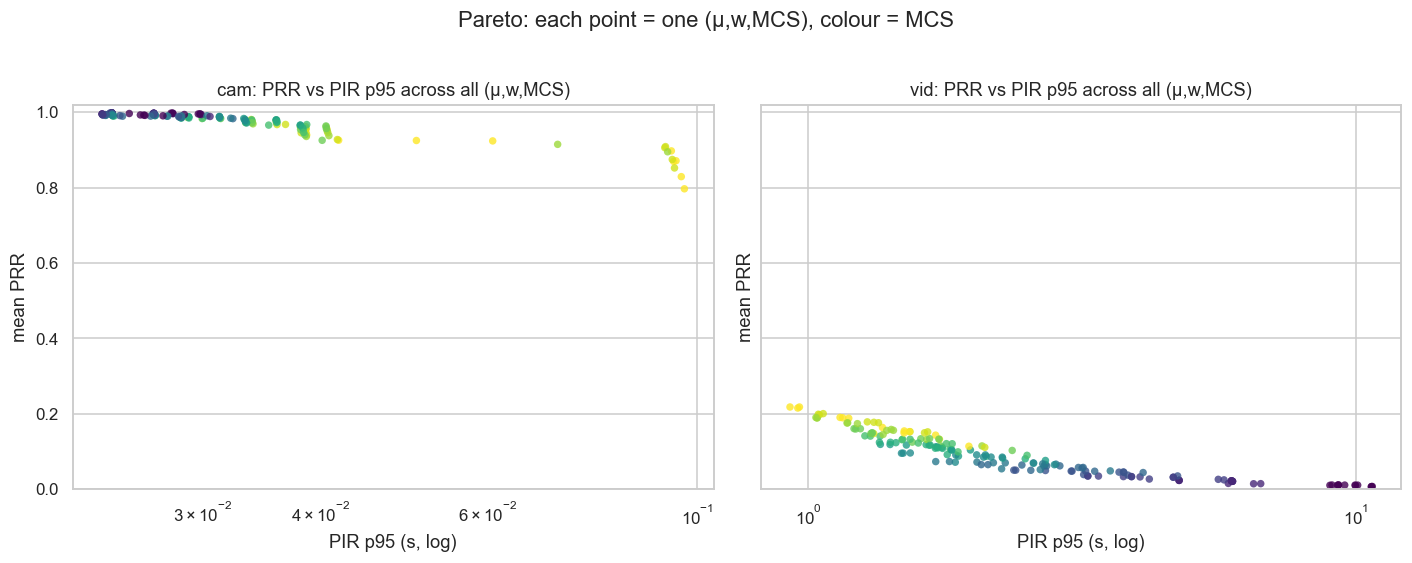

In [20]:
# 6b — PRR vs PIR_p95 Pareto frontier (lower-PIR + higher-PRR is better).
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=False, sharey=True)
for ax, flow, color in zip(axes, ('cam', 'vid'), ('#2a9d8f','#e76f51')):
    sub = phy_agg[phy_agg['flow']==flow]
    ax.scatter(sub['pir_p95'], sub['prr'], c=sub['mcs'], cmap='viridis',
               s=24, alpha=0.8, edgecolors='none')
    ax.set_xscale('log'); ax.set_ylim(0, 1.02)
    ax.set_title(f'{flow}: PRR vs PIR p95 across all (μ,w,MCS)')
    ax.set_xlabel('PIR p95 (s, log)'); ax.set_ylabel('mean PRR')
fig.suptitle('Pareto: each point = one (μ,w,MCS), colour = MCS', y=1.02)
plt.tight_layout(); plt.show(); plt.close(fig)

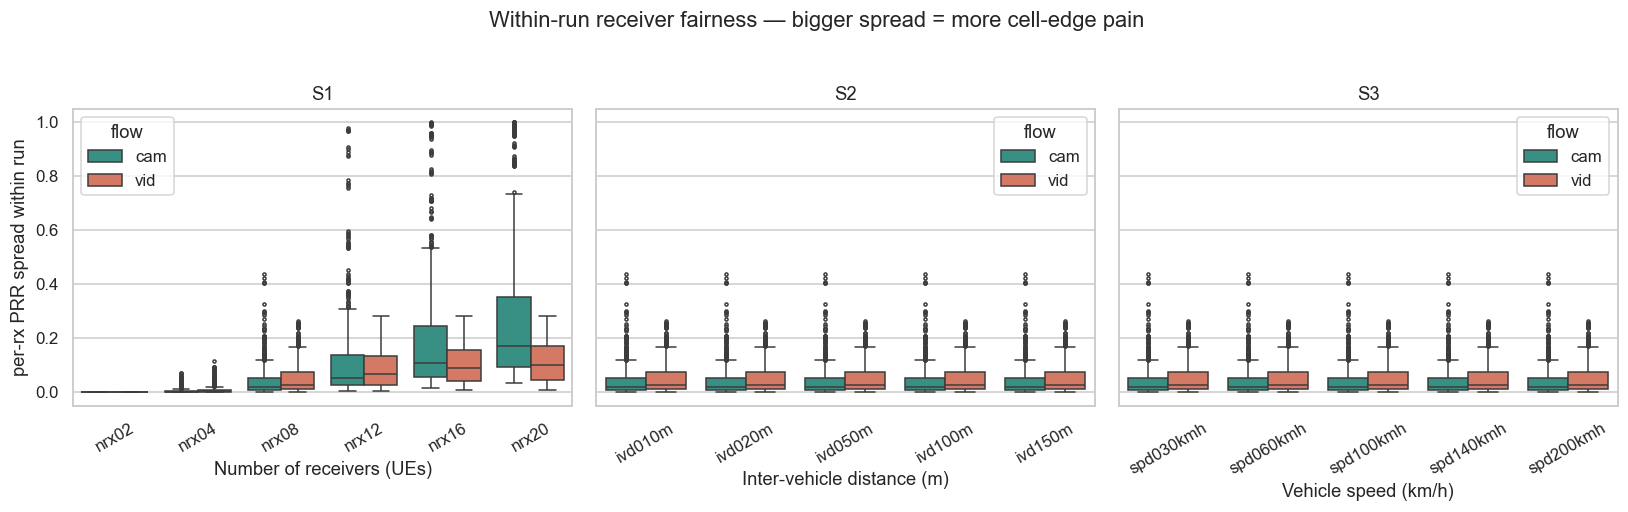

In [21]:
# 6c — within-run receiver fairness: spread (max − min) of per-rx PRR.
fair = (df_rx.groupby(['stem','scen','cond','iter_value','mu','w','mcs','seed','flow'])['prr']
             .agg(['min','median','max'])
             .rename(columns={'min':'prr_min','median':'prr_med','max':'prr_max'})
             .reset_index())
fair['spread'] = fair['prr_max'] - fair['prr_min']
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, scen in zip(axes, ('s1','s2','s3')):
    sub = fair[fair['scen']==scen]
    sns.boxplot(data=sub.sort_values('iter_value'),
                x='cond', y='spread', hue='flow',
                palette={'cam':'#2a9d8f','vid':'#e76f51'}, fliersize=2, ax=ax,
                order=sub.drop_duplicates('cond').sort_values('iter_value')['cond'].tolist())
    ax.set_title(f'{scen.upper()}'); ax.set_xlabel(SCEN_AXIS[scen][0])
    ax.set_ylabel('per-rx PRR spread within run')
    ax.tick_params(axis='x', rotation=30)
fig.suptitle('Within-run receiver fairness — bigger spread = more cell-edge pain', y=1.03)
plt.tight_layout(); plt.show(); plt.close(fig)

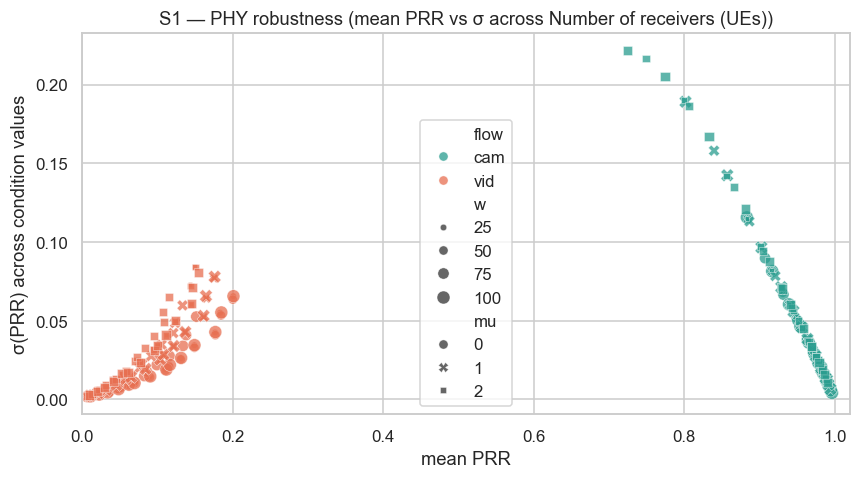

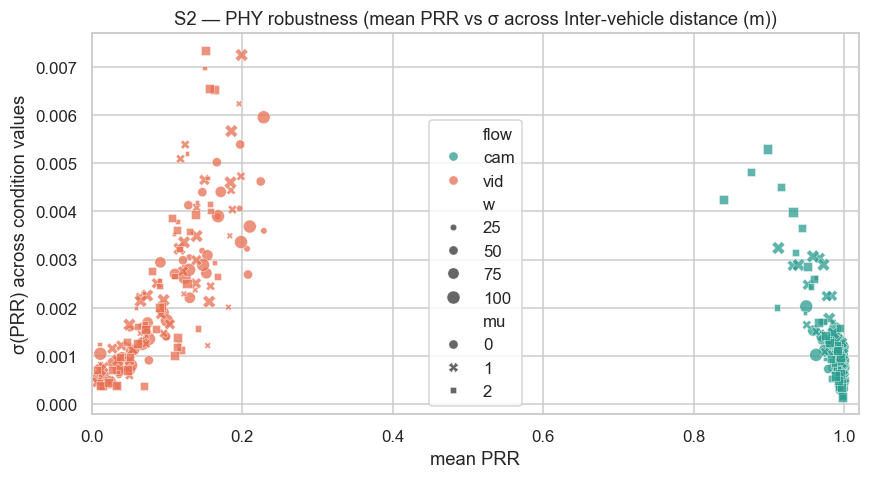

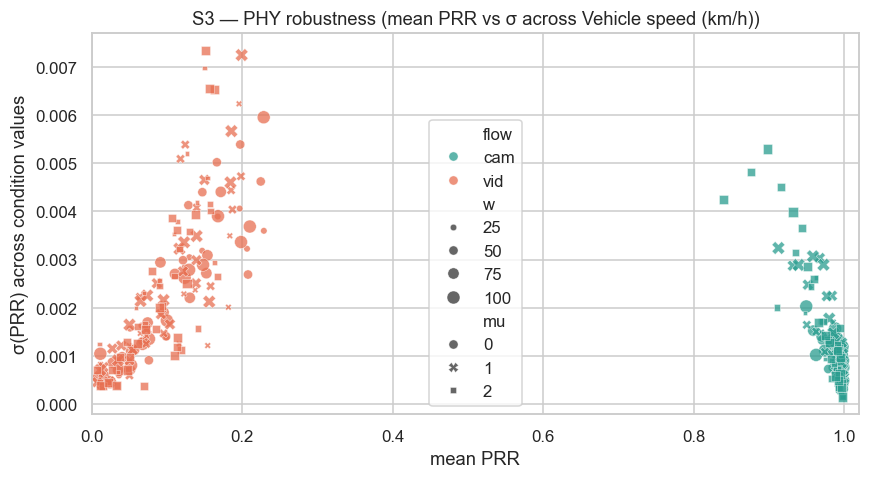


Top-10 most-robust (high min-PRR + low max-σ across all scenarios pooled):
Empty DataFrame
Columns: [mu, w, mcs, prr_mean_cam, prr_mean_vid, prr_std_cam, prr_std_vid, min_mean, max_std]
Index: []


In [22]:
# 6d — Stability across iteration: σ(PRR) across cond values per (μ,w,MCS,flow).
stab = (df_run.groupby(['scen','mu','w','mcs','flow'])
              .agg(prr_mean=('prr','mean'), prr_std=('prr','std'),
                   prr_min=('prr','min'), prr_max=('prr','max'))
              .reset_index())
for scen in ('s1','s2','s3'):
    sub = stab[(stab['scen']==scen)]
    fig, ax = plt.subplots(figsize=(9, 4.5))
    sns.scatterplot(data=sub, x='prr_mean', y='prr_std', hue='flow', style='mu', size='w',
                    palette={'cam':'#2a9d8f','vid':'#e76f51'}, alpha=0.75, ax=ax)
    ax.set_title(f'{scen.upper()} — PHY robustness (mean PRR vs σ across {SCEN_AXIS[scen][0]})')
    ax.set_xlabel('mean PRR'); ax.set_ylabel('σ(PRR) across condition values')
    ax.set_xlim(0, 1.02)
    plt.show(); plt.close(fig)

# Print top-5 most-robust (low std, high mean) for joint min(cam,vid)
stab_w = stab.pivot_table(index=['mu','w','mcs'], columns='flow', values=['prr_mean','prr_std'])
stab_w.columns = [f'{a}_{b}' for a,b in stab_w.columns]
stab_w = stab_w.reset_index()
stab_w['min_mean'] = stab_w[['prr_mean_cam','prr_mean_vid']].min(axis=1)
stab_w['max_std']  = stab_w[['prr_std_cam','prr_std_vid']].max(axis=1)
print('\nTop-10 most-robust (high min-PRR + low max-σ across all scenarios pooled):')
print(stab_w[stab_w['min_mean']>0.7].sort_values('max_std').head(10).round(3).to_string(index=False))

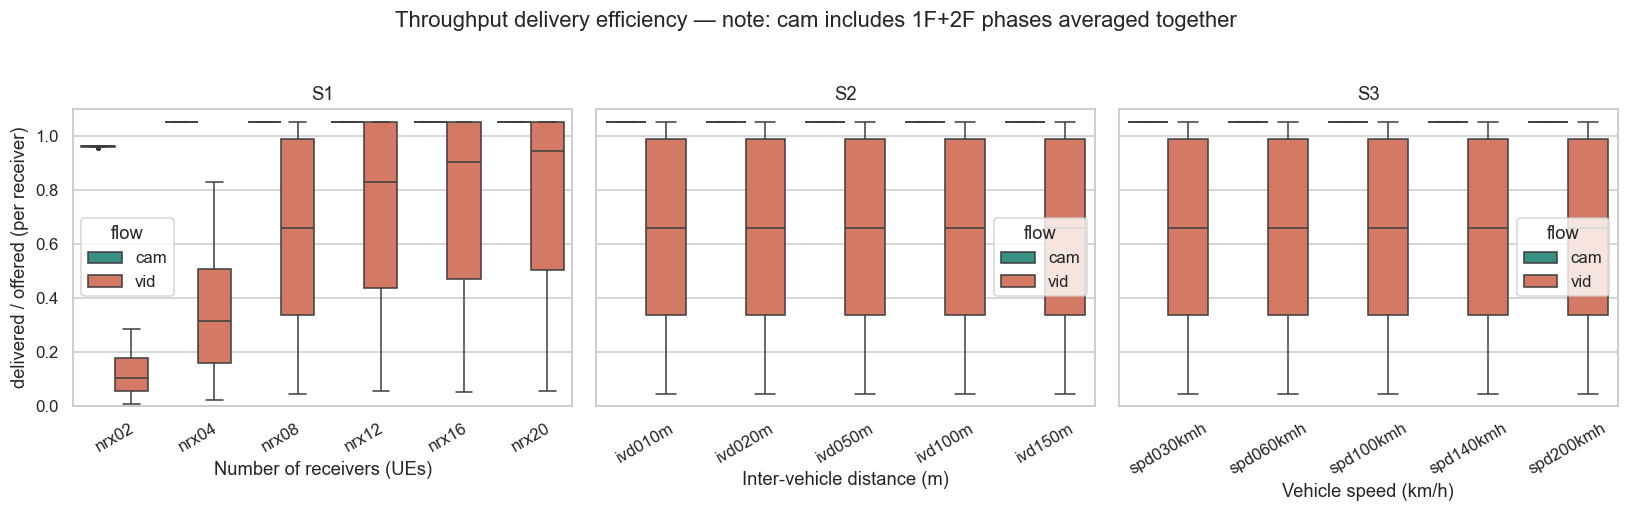

In [23]:
# 6e — Throughput delivery efficiency = delivered/offered per flow.
# offered_per_rx = tx_count * pktSize × 8 / duration / 1000 ; we'll use rx_bytes vs expected_bytes proxy.
OFFERED_KBPS = {'cam': 200.0, 'vid': 2000.0}  # nominal flow rates
df_run['offered_kbps'] = df_run['flow'].map(OFFERED_KBPS)
df_run['delivery_eff'] = (df_run['throughput_kbps'] / df_run['offered_kbps']).clip(upper=1.05)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, scen in zip(axes, ('s1','s2','s3')):
    sub = df_run[df_run['scen']==scen].copy()
    sns.boxplot(data=sub.sort_values('iter_value'),
                x='cond', y='delivery_eff', hue='flow',
                palette={'cam':'#2a9d8f','vid':'#e76f51'}, fliersize=2, ax=ax,
                order=sub.drop_duplicates('cond').sort_values('iter_value')['cond'].tolist())
    ax.set_title(f'{scen.upper()}'); ax.set_xlabel(SCEN_AXIS[scen][0])
    ax.set_ylabel('delivered / offered (per receiver)')
    ax.tick_params(axis='x', rotation=30); ax.set_ylim(0, 1.1)
fig.suptitle('Throughput delivery efficiency — note: cam includes 1F+2F phases averaged together', y=1.03)
plt.tight_layout(); plt.show(); plt.close(fig)

### Reading the results

- **PRR vs scenario iteration (§1)** is the headline plot: for each (μ, w) you can read off the MCS family that survives as the load grows (s1), the receivers spread out (s2), or the geometry shifts (s3). The dashed envelope is the achievable upper bound per iteration value.
- **Per-receiver best MCS (§2)** shows whether different receivers prefer different MCSs in the same run — the basis for any per-link adaptive scheme.
- **Optimal MCS heatmaps (§3)** + **Δ heatmap** quantify how much the optimum shifts when the video flow comes online. A negative Δ at high N_Rx means the contention pushes the system toward a more conservative MCS than the platoon-only optimum.
- **PRR/PIR vs MCS (§4)** isolates the link curve from the contention curve: the cam-vid gap at any MCS is purely the contention/priority effect because both flows share the same PHY config.
- **Leaderboards (§5)** — the joint-min ranking is the right metric if you care about *both* flows being usable; sort by `prr_cam` if the platoon flow is mission-critical and `vid` is best-effort.
- **Bonus 6a** is the cleanest visualisation of cam–vid coupling: when the dots fall well below the y=x line, the platoon is being protected by priority despite the heavier video load; when they cluster on/below the diagonal, video is dragging cam down.
- **Bonus 6c** highlights cell-edge unfairness — useful when the absolute PRR is fine but a few receivers in each run are starving.